In [2]:
# SETUP - run this cell once, then any cell below on its own #################
#
# Every other cell in this notebook needs this cell and nothing else. Packages,
# paths, the shared styling constants and the shared spline helper all live
# here, so after reopening the notebook you run this cell plus whichever figure
# you want to redraw, and never the whole notebook.

# ---- packages -------------------------------------------------------------
import os
import re
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
import xarray as xr
import yaml
from IPython.display import display
from matplotlib import colormaps
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure
from matplotlib.ticker import MaxNLocator
from tqdm import tqdm

# rasterio is needed only by the vulnerability map, and is not installed in
# gbd_env (which has no GeoTIFF reader at all). Importing it optionally keeps
# every other cell working there; the map cell says what to do if it's absent.
try:
    import rasterio
except ModuleNotFoundError:
    rasterio = None

# from db_queries import get_location_metadata

# ---- paths ----------------------------------------------------------------

# Raw data
RAW_DATA_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_10_08.01/data.parquet"
RAW_DATA_5q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/training_data/2026_10_07.01/data.parquet"

# Training results
TRAINING_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_10_08.02"
TRAINING_5q28_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/models/2026_10_15.01/"
TRAINING_LBW_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/lbw/models/2026_10_16.04/"
TRAINING_ANEMIA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/anemia/models/2026_10_15.01/"

# Prediction results
RESULTS_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_10_08.01/ssp245_shifted.parquet"
RESULTS_5q28_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_16.01/ssp245_shifted.parquet"
RESULTS_5q0_SINGLE_RUN_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_01.01/ssp245_shifted.parquet"
RESULTS_LBW_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/lbw/results/2026_10_19.01/"
RESULTS_ANEMIA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/anemia/results/2026_10_16.01/"
# RESULTS_ANEMIA_PATH


PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)

# ---- shared heatmap styling -----------------------------------------------
# Sized for a 12.6 x 4.2in slot in a deck, so the png drops in at its native
# aspect and nothing has to be rescaled. Ten income rows in 4.2in is tight, so
# the annotations are smaller than the tick labels. Every heatmap figure below
# takes its sizes from these three, so changing them here moves all of them.
NEO_FIGSIZE = (12.6, 4.2)
NEO_TICK_SIZE = 11
NEO_ANNOT_SIZE = 10

# The ten consumption_pd decile edges the pipeline's neonatal branch uses.
# Shared by the neonatal and the child mortality figures, which is what lets
# the two be read side by side.
NEO_Y_BINS = [
    0,
    0.784781,
    1.180789,
    1.541445,
    1.950251,
    2.465952,
    3.103463,
    4.003564,
    5.541124,
    9.413681,
    112.879922,
]

# ---- shared spline styling and helper -------------------------------------
SPL_FIGSIZE = (10, 6)
SPL_LINE, SPL_BAND = "#2c3e50", "#3498db"
# Larger than matplotlib's default 10. The tick numbers are the only text left
# on these figures, and the y scale is log-odds, so they have to carry the
# whole magnitude from the back of a room.
SPL_TICK_SIZE, SPL_LEGEND_SIZE = 14, 14


def plot_spline_effect_clean(effect_df, filepath=None):
    """plot_scam_spline with the rug, knots, title, x padding, zero line and
    axis labels gone.

    `effect_df` is a pipeline `spline_effect_*.parquet`: value / effect / se.
    The band is the pipeline's own effect +/- 1.96 * se.
    """
    fig, ax = plt.subplots(figsize=SPL_FIGSIZE)
    ax.plot(
        effect_df["value"],
        effect_df["effect"],
        color=SPL_LINE,
        lw=2.5,
        label="Partial Effect",
    )
    ax.fill_between(
        effect_df["value"],
        effect_df["effect"] - 1.96 * effect_df["se"],
        effect_df["effect"] + 1.96 * effect_df["se"],
        color=SPL_BAND,
        alpha=0.2,
        label="95% CI",
    )
    # pin the axis to the curve, and stop matplotlib adding its default 5%
    ax.set_xmargin(0)
    ax.set_xlim(effect_df["value"].min(), effect_df["value"].max())
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=SPL_TICK_SIZE)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(frameon=True, loc="best", fontsize=SPL_LEGEND_SIZE)
    fig.tight_layout()
    if filepath:
        fig.savefig(filepath, dpi=300)
    return fig, ax


# ---- scenario lines and cumulative difference tables ----------------------
# These read the pipeline's own `shifted_prevalence.parquet` and reproduce the
# two outputs the residual step makes - superregion_prev.pdf and
# table1_cumulative_case_counts.csv - in the deck's format. No extra modelling:
# the file already holds all three scenarios at the most-detailed locations,
# so this is aggregation plus styling.
FHS_POP_PATH = "/mnt/share/forecasting/data/32/future/population/future_population_s130v41/population.nc"
FHS_HIERARCHY_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/fhs_hierarchy.parquet"

SCENARIO_ORDER = ["ssp126", "ssp245", "ssp585"]
SCENARIO_COLOURS = ["#2a78d6", "#52514e", "#eb6834"]
SCENARIO_DISPLAY = {"ssp126": "RCP 2.6", "ssp245": "RCP 4.5", "ssp585": "RCP 8.5"}
SCENARIO_LEGEND_TITLE = "Representative Control Pathways (RCP) Scenarios"
SCENARIO_PAIRS = [("ssp585", "ssp126"), ("ssp585", "ssp245"), ("ssp245", "ssp126")]
FIRST_FORECAST_YEAR = 2024
ANALYSIS_YEARS = [2050, 2100]
# Live births, for indicators defined per birth (LBW here). Same file and same
# split as the FHS mortality notebook: release 32, scenario 130, national only
# with no sex dimension, divided below that by ages 2 + 3 population share.
LIVE_BIRTHS_PATH = "/mnt/share/forecasting/data/32/future/live_births/future_livebirth_s130v97/live_births.nc"
# maternal age groups 15-19 .. 45-49; the file also carries 24, their sum,
# which must be left out or every birth is counted twice
LIVE_BIRTHS_MATERNAL_AGES = [8, 9, 10, 11, 12, 13, 14]
NEONATAL_POP_PARTS = [2, 3]

# constants.AGE_GROUP_AGGREGATES: the only ids that are not in the population
# file directly and have to be summed from parts
AGE_GROUP_AGGREGATES = {
    4: [388, 389],
    5: [238, 34],
    42: [2, 3],
    1: [2, 3, 388, 389, 238, 34],
}

LBW_PLOT_FILE = "lbw_superregion_scenarios.png"
LBW_TABLE_FILE = "lbw_cumulative_scenario_differences.csv"
LBW_YLABEL = "Low birthweight prevalence"
ANEMIA_PLOT_FILE = "anemia_women_15_49_superregion_scenarios.png"
ANEMIA_TABLE_FILE = "anemia_women_15_49_cumulative_scenario_differences.csv"
ANEMIA_YLABEL = "Anemia prevalence among women aged 15-49"


def load_population_by_age(age_group_ids):
    """Population per requested age group, expanding aggregates to parts."""
    frames = []
    pop = xr.open_dataset(FHS_POP_PATH)["draws"].mean("draw").squeeze(drop=True)
    for a in age_group_ids:
        parts = AGE_GROUP_AGGREGATES.get(a, [a])
        f = (
            pop.sel(age_group_id=parts)
            .sum("age_group_id")
            .to_dataframe(name="population")
            .reset_index()[["location_id", "year_id", "sex_id", "population"]]
        )
        f["age_group_id"] = a
        frames.append(f)
    return pd.concat(frames, ignore_index=True)


def load_live_births_weights():
    """Live births at every most-detailed location, by year and sex.

    The births file is national only and has no sex dimension, so each
    country's births are divided among its most-detailed (location, sex)
    cells in proportion to their ages 2 + 3 population:

        births[l, s] = births[country] * pop23[l, s] / pop23[country]

    National totals are preserved exactly. Identical to the function in
    notebooks/child_mortality/apply_scenario_differences_to_FHS.ipynb, so all
    three per-birth indicators are weighted by the same births.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    md = hier.loc[
        hier["most_detailed"] == 1, ["location_id", "path_to_top_parent"]
    ].copy()
    # the level-3 ancestor in each location's own path is its country
    md["country_id"] = md["path_to_top_parent"].str.split(",").str[3].astype(int)
    md = md[["location_id", "country_id"]]

    births = (
        xr.open_dataset(LIVE_BIRTHS_PATH)["livebirths"]
        .sel(age_group_id=LIVE_BIRTHS_MATERNAL_AGES)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="country_births")
        .reset_index()[["location_id", "year_id", "country_births"]]
        .rename(columns={"location_id": "country_id"})
    )
    pop = (
        xr.open_dataset(FHS_POP_PATH)["draws"]
        .sel(age_group_id=NEONATAL_POP_PARTS)
        .sum("age_group_id")
        .mean("draw")
        .squeeze(drop=True)
        .to_dataframe(name="population")
        .reset_index()[["location_id", "year_id", "sex_id", "population"]]
        .merge(md, on="location_id", how="inner")
    )
    pop["country_pop"] = pop.groupby(["country_id", "year_id"])["population"].transform(
        "sum"
    )
    w = pop.merge(births, on=["country_id", "year_id"], how="inner")
    w["births"] = w["country_births"] * w["population"] / w["country_pop"]
    return w[["location_id", "year_id", "sex_id", "births"]]


def build_measure_counts(results_dir, weight="population", sex_ids=None):
    """Cases and their weight at the globe and each super region.

    prevalence x weight, summed over the most-detailed locations under each
    aggregate and over age and sex. `path_to_top_parent` lists every
    ancestor, so exploding it rolls each location into all of them at once.

    weight="population" is the pipeline's get_count_draws: right for a
    prevalence in a standing population, such as anemia, where prevalence x
    population genuinely is the number of people affected.

    weight="births" is for an indicator defined per birth, such as LBW. The
    pipeline weights LBW by the age group 2 population, the babies aged 0-6
    days alive at one moment, which is about one week of births (live births /
    age 2 population = 52.2 in 2024, against 365/7 = 52.1). Multiplying a
    per-birth share by that counts one week's babies instead of a year's.
    Live births fix the count; for the rate it barely matters, because the
    weight is close to proportional to births and largely cancels.

    sex_ids keeps only those sexes before anything is weighted or summed, so
    rates and counts describe that group alone (anemia: [2], women 15-49).
    None keeps every sex in the results.
    """
    path = Path(results_dir) / "shifted_prevalence.parquet"
    if not path.exists():
        msg = (
            f"{path} not found. The residual step has not produced it for this "
            "results version yet; run `strun residual` first."
        )
        raise FileNotFoundError(msg)

    prev = (
        pd.read_parquet(path).clip(0, 1).mean(axis=1).rename("prevalence").reset_index()
    )
    if sex_ids is not None:
        prev = prev[prev["sex_id"].isin(sex_ids)]
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    if weight == "population":
        # population per age group, so a measure spanning several of them
        # (anemia) is weighted correctly before age is collapsed
        d = prev.merge(
            load_population_by_age(sorted(prev["age_group_id"].unique())),
            on=["location_id", "year_id", "sex_id", "age_group_id"],
            how="inner",
        ).rename(columns={"population": "weight"})
    elif weight == "births":
        ages = prev["age_group_id"].unique()
        if len(ages) != 1:
            msg = f"births weighting needs a single age group, got {sorted(ages)}"
            raise ValueError(msg)
        d = prev.merge(
            load_live_births_weights(),
            on=["location_id", "year_id", "sex_id"],
            how="inner",
        ).rename(columns={"births": "weight"})
    else:
        msg = f"weight must be 'population' or 'births', got {weight!r}"
        raise ValueError(msg)
    d["count"] = d["prevalence"] * d["weight"]

    anc = hier.loc[
        hier["most_detailed"] == 1, ["location_id", "path_to_top_parent"]
    ].copy()
    anc["agg_id"] = anc["path_to_top_parent"].str.split(",")
    anc = anc.explode("agg_id")
    anc["agg_id"] = anc["agg_id"].astype(int)
    table_locs = set(hier.loc[hier["level"] < 2, "location_id"])
    anc = anc[anc["agg_id"].isin(table_locs)][["location_id", "agg_id"]]

    out = (
        d.merge(anc, on="location_id")
        .groupby(["agg_id", "scenario", "year_id"], as_index=False)[["count", "weight"]]
        .sum()
        .rename(columns={"agg_id": "location_id"})
    )
    out["rate"] = out["count"] / out["weight"]
    return out


def cumulative_difference_table(counts, count_label="cases"):
    """Cumulative cases by scenario, the differences, and each as a percent.

    At ANALYSIS_YEARS, in whole cases. For each location the three
    scenarios' own cumulative totals come first, then the three differences:

        cumulative[s]   = sum over 2024..year of count[s]
        cases           = cumulative[A] - cumulative[B]
        pct_change_from_lower_scenario
                        = 100 * (cumulative[A] - cumulative[B]) / cumulative[B]

    B is always the lower-emission scenario of the pair (ssp126 under ssp245
    under ssp585), so the percent reads as "how many more cases the higher-
    emission pathway brings, relative to the lower one". It is blank on the
    three level rows. Every value is rounded on its own, so a difference can
    sit one case away from the subtraction of its two rounded level rows.
    Same layout as the mortality tables in apply_scenario_differences_to_FHS.

    count_label names the count column. "cases" fits a per-birth measure
    such as LBW, where a year's count is a number of babies. For a
    prevalence in a standing population, such as anemia, each year's count
    is the people affected that year, so the cumulative sum is person-years.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    cum = counts.query("year_id >= @FIRST_FORECAST_YEAR").sort_values("year_id").copy()
    cum["cum_count"] = cum.groupby(["location_id", "scenario"])["count"].cumsum()
    wide = cum.pivot_table(
        index=["location_id", "year_id"], columns="scenario", values="cum_count"
    )
    rows = []
    for s in SCENARIO_ORDER:
        d = wide[s].rename("value").reset_index()
        d["pct"] = np.nan
        d["scenario"] = s
        rows.append(d)
    for a, b in SCENARIO_PAIRS:
        d = (wide[a] - wide[b]).rename("value").reset_index()
        d["pct"] = (100 * (wide[a] - wide[b]) / wide[b]).to_numpy()
        d["scenario"] = f"{a} - {b}"
        rows.append(d)
    row_order = {
        lab: k
        for k, lab in enumerate(
            SCENARIO_ORDER + [f"{a} - {b}" for a, b in SCENARIO_PAIRS]
        )
    }
    table = (
        pd.concat(rows)
        .query("year_id in @ANALYSIS_YEARS")
        .merge(
            hier[["location_id", "location_name", "sort_order"]],
            on="location_id",
            how="left",
        )
    )
    table["_row"] = table["scenario"].map(row_order)
    table = table.sort_values(["year_id", "sort_order", "_row"])
    table[count_label] = table["value"].round().astype("int64")
    table["pct_change_from_lower_scenario"] = table["pct"].round(2)
    return table[
        [
            "year_id",
            "location_name",
            "scenario",
            count_label,
            "pct_change_from_lower_scenario",
        ]
    ].reset_index(drop=True)


def plot_superregion_rates(counts, ylabel, ncol=4):
    """Prevalence by scenario, one panel per globe/super region.

    Four across, so the globe and the seven super regions fill two rows
    exactly, with one legend for the whole figure underneath and a shared y
    axis so the panels are comparable.
    """
    hier = pd.read_parquet(FHS_HIERARCHY_PATH)
    locs = (
        hier[hier["location_id"].isin(counts.location_id.unique())]
        .query("level < 2")
        .sort_values("sort_order")
    )
    nrow = int(np.ceil(len(locs) / ncol))
    fig, axes = plt.subplots(
        nrow, ncol, figsize=(4.0 * ncol, 3.4 * nrow), sharex=True, sharey=True
    )
    handles = []
    for ax, (_, loc) in zip(axes.flatten(), locs.iterrows()):
        panel = counts[counts["location_id"] == loc["location_id"]]
        for scen, colour in zip(SCENARIO_ORDER, SCENARIO_COLOURS):
            s = panel[panel["scenario"] == scen].sort_values("year_id")
            (line,) = ax.plot(s["year_id"], s["rate"], color=colour, lw=2)
            if len(handles) < len(SCENARIO_ORDER):
                line.set_label(SCENARIO_DISPLAY[scen])
                handles.append(line)
        ax.set_title(loc["location_name"], fontsize=12)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.tick_params(labelsize=10)
    for ax in axes.flatten()[len(locs) :]:
        ax.set_visible(False)
    # left margin kept free for the shared label, which tight_layout ignores
    fig.supylabel(ylabel, fontsize=12, x=0.005)
    fig.tight_layout(rect=[0.02, 0.08, 1, 1])
    fig.legend(
        handles=handles,
        title=SCENARIO_LEGEND_TITLE,
        loc="lower center",
        ncol=len(SCENARIO_ORDER),
        frameon=False,
        fontsize=11,
        title_fontsize=12,
        bbox_to_anchor=(0.5, 0.0),
    )
    return fig


def scenario_outputs(
    results_dir,
    ylabel,
    plot_file,
    table_file,
    weight="population",
    sex_ids=None,
    count_label="cases",
):
    """Line plots and the cumulative difference table for one measure."""
    counts = build_measure_counts(results_dir, weight=weight, sex_ids=sex_ids)
    table = cumulative_difference_table(counts, count_label=count_label)
    fig = plot_superregion_rates(counts, ylabel)
    fig.savefig(os.path.join(PLOT_OUTPUT, plot_file), dpi=200, bbox_inches="tight")
    table.to_csv(
        os.path.join(PLOT_OUTPUT, table_file), index=False, encoding="utf-8-sig"
    )
    return counts, table, fig


# ---- vulnerability maps ---------------------------------------------------------
# Pixel-level maps of a scenario difference, drawn from the rasters inference
# writes when run with --save-rasters. Raw model output: no residual model and
# no GBD anchor. For a SCENARIO difference that is what you want - the
# residual and the anchor are added identically to every scenario and cancel
# out of ssp585 - ssp126, and the residual step's zero-clipping is what would
# otherwise hide much of the climate effect.
RASTER_ROOT = Path(
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition"
)
RASTER_VERSION = "2026_10_23.01"  # the raster runs, one per measure
RASTER_YEAR = 2100
RASTER_SEX_ID = 2  # the raster runs were made for sex 2 only
CHILD_STRATA = [
    "age_3_m",
    "age_6_m",
    "age_12_m",
    "age_24_m",
    "age_36_m",
    "age_48_m",
    "age_60_m",
]
RASTER_SCENARIO_NAMES = {
    "ssp126": "SSP1 2.6",
    "ssp245": "SSP2 4.5",
    "ssp585": "SSP5 8.5",
}
U5_MAP_LABEL = "Under-5 Mortality Rate\nper 1000 births"
U5_MAP_FILE = "under5_mortality_scenario_diff.png"


def read_raster(path):
    if rasterio is None:
        msg = (
            "rasterio is not installed in this kernel, so the vulnerability "
            "map cannot read its GeoTIFFs. gbd_env has no GeoTIFF reader; run "
            "this notebook in an environment that has rasterio (cgf does)."
        )
        raise ModuleNotFoundError(msg)
    with rasterio.open(path) as src:
        return src.read(1)


def raster_survival(measure, scenario, ages):
    """Probability of dying across `ages`, pixel by pixel.

    For one age group it is the raster itself. For several, the strata are
    chained with the survival identity the forecast step uses on location
    values: 1 - product over strata of (1 - q).
    """
    folder = RASTER_ROOT / measure / "results" / RASTER_VERSION
    paths = [folder / f"{RASTER_YEAR}_{scenario}_{a}_{RASTER_SEX_ID}.tif" for a in ages]
    missing = [p.name for p in paths if not p.exists()]
    if missing:
        msg = f"{measure} {scenario}: missing {missing}"
        raise FileNotFoundError(msg)
    survive = 1.0 - read_raster(paths[0])
    for p in paths[1:]:
        survive *= 1.0 - read_raster(p)
    return 1.0 - survive


def under5_raster(scenario):
    """5q0 = 1 - (1 - 28q0)(1 - 5q28), pixel by pixel.

    28q0 is the neonatal raster (age group 42); 5q28 chains the seven child
    survival strata, age_3_m to age_60_m.
    """
    q28 = raster_survival("neonatal_mortality", scenario, [42])
    q5q28 = raster_survival("child_mortality", scenario, CHILD_STRATA)
    return 1.0 - (1.0 - q28) * (1.0 - q5q28)


def plot_raster_diff(data, label, output_path):
    """Diverging map of a raster difference, 0 mapped to white.

    Copied from rra_climate_health/inference/raster_diagnostics.py in the _2
    clone (Victor Vilchis Tella), so the map looks exactly like the
    pipeline's. The one change: it returns the figure so the notebook can show
    it, instead of only writing it.
    """
    finite = np.isfinite(data)
    if not finite.any():
        print(f"No finite values to plot for {output_path.name}; skipping.")
        return None

    # crop to the bounding box of non-NaN cells (drops the empty polar bands)
    rows, cols = np.where(finite)
    data = data[rows.min() : rows.max() + 1, cols.min() : cols.max() + 1]

    # color limits, with 0 kept as an endpoint
    vmin, vmax = np.nanpercentile(data, [1, 99])
    vmin, vmax = min(vmin, 0.0), max(vmax, 0.0)

    # slice RdBu_r so that 0 is white, without carrying unused colors
    m = max(-vmin, vmax)
    if m == 0:
        print(f"Difference is zero everywhere for {output_path.name}; skipping.")
        return None
    cmap = LinearSegmentedColormap.from_list(
        "slice",
        colormaps["RdBu_r"](
            np.linspace((vmin + m) / (2 * m), (vmax + m) / (2 * m), 256)
        ),
    )
    cmap.set_bad("#ececec")

    # figure matches the map's aspect, full slide width
    h, w = data.shape
    cbar_frac = 0.12  # share of figure width given to the colorbar
    fig_w = 13.333
    map_w = fig_w * (1 - cbar_frac)  # map's width in inches
    fig = Figure(figsize=(fig_w, map_w * h / w), dpi=200)

    ax = fig.add_axes([0, 0, 1 - cbar_frac, 1])
    im = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_axis_off()
    cbar_h = 0.78  # fraction of figure height
    cax = fig.add_axes([1 - cbar_frac + 0.02, (1 - cbar_h) / 2, 0.016, cbar_h])

    cbar = fig.colorbar(im, cax=cax, extend="both")
    cbar.set_label(label, fontsize=13, labelpad=12)
    cbar.ax.tick_params(labelsize=12, length=3, pad=4)
    cbar.outline.set_linewidth(0.5)

    fig.savefig(output_path, dpi=200, facecolor="white")
    print(f"Wrote {output_path}")
    return fig


print("setup ready - every cell below now runs standalone")

setup ready - every cell below now runs standalone


# 1. Heatmaps

### Create heatmaps for neonatal mortality

In [ ]:
# Neonatal mortality heatmaps: data, with RE, without RE ######################
# Bins and colour range follow the pipeline's own neonatal branch in
# training.training_diagnostics.plot_model_heatmaps (rra-climate-health, the
# clone `strun` resolves to): x = [1, 3, 8, 15, 22, 31] with zero-exposure
# births dropped, y = the ten consumption_pd edges, scale fixed at 20-50 deaths
# per 1000, values x1000.
#
# The predictions differ from the pipeline's on purpose. The pipeline plots
# `fits` and `no_re_fits` straight off the fitted frame, so every row carries
# its own sex, income level and rainfall, and moving between cells moves those
# too - the monotone spline constraints do not survive that averaging. Here the
# recipe from notebooks/neonatal/read_predict_models.R (the 11/18 block) is used
# instead: copy the fitted frame, overwrite every covariate that is NOT an axis
# with one representative value, and re-predict. The axes keep their observed
# joint distribution, so the cells are still the real ones; only the nuisance
# terms are flattened.
#
#   sex_id                         mode  (categorical; R pinned one level too)
#   consumption_median_RT          mean  (on the log-transformed scale it is fit on)
#   total_precipitation_prev_0_mo  mean
#   ihme_loc_id                    kept for the with-RE panel, excluded for without
#
# Those predictions are built by a helper that needs rpy2 and the 2.5 GB model
# pickle, so they are cached beside the model rather than recomputed here. The
# build was checked by first reproducing the stored `fits` and `no_re_fits`
# exactly (max absolute difference 0.0) before any covariate was flattened.
NEO_MV = "2026_10_08.02"
NEO_X = "days_over_30C_prev_0_mo"
NEO_Y = "consumption_pd"
NEO_MULT = 1000
NEO_X_BINS = [1, 3, 8, 15, 22, 31]
NEO_VMIN, NEO_VMAX = 20, 50
# NEO_Y_BINS, NEO_FIGSIZE, NEO_TICK_SIZE and NEO_ANNOT_SIZE are in the setup
# cell, because every other heatmap figure in this notebook shares them.
NEO_PANELS = [
    ("neonatal_mortality", "Data"),
    ("avg_fits", "Predicted, with RE"),
    ("avg_no_re_fits", "Predicted, without RE"),
]
NEO_AVG_FILE = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
NEO_OUT = f"{PLOT_OUTPUT}neonatal_mortality_heatmaps.png"

if not NEO_AVG_FILE.exists():
    msg = (
        f"{NEO_AVG_FILE} not found. Build it with the averaged-covariate helper "
        "(needs rpy2 and scam, so run it in the cluster-dev pixi env, not gbd_env)."
    )
    raise FileNotFoundError(msg)

_neo_raw = pd.read_parquet(
    RAW_DATA_28q0_PATH, columns=[NEO_X, NEO_Y, "neonatal_mortality"]
)
_neo = pd.read_parquet(NEO_AVG_FILE)
if len(_neo) != len(_neo_raw):
    raise ValueError(f"cached predictions {len(_neo):,} vs raw {len(_neo_raw):,} rows")
for _c in (NEO_X, NEO_Y):
    if not np.allclose(_neo[_c].to_numpy(), _neo_raw[_c].to_numpy()):
        raise ValueError(
            f"{_c} differs between the cached predictions and the raw extract"
        )

# the pipeline drops zero-exposure births before binning, so the first bin is
# [1, 3) rather than a zero column
_neo["_x"] = pd.cut(
    _neo.loc[_neo[NEO_X] > 0, NEO_X], bins=NEO_X_BINS, include_lowest=True, right=False
)
_neo["_y"] = pd.cut(_neo[NEO_Y], bins=NEO_Y_BINS, include_lowest=True, right=False)
_neo_kept = _neo[["_x", "_y"]].notna().all(axis=1)
print(
    f"neonatal heatmap: {len(_neo):,} births, {int((~_neo_kept).sum()):,} outside the "
    f"bin edges ({100 * (1 - _neo_kept.mean()):.1f}%, mostly zero-exposure)"
)

_neo_mats = {
    k: _neo.groupby(["_y", "_x"], observed=False)[k].mean().unstack() * NEO_MULT
    for k, _ in NEO_PANELS
}
_neo_n = _neo.groupby(["_y", "_x"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 3, figsize=NEO_FIGSIZE, constrained_layout=True)
_bounds = np.arange(
    NEO_VMIN, NEO_VMAX + (NEO_VMAX - NEO_VMIN) / 10, (NEO_VMAX - NEO_VMIN) / 10
)
_cmap = plt.get_cmap("RdYlBu_r", len(_bounds) - 1)
_norm = mcolors.BoundaryNorm(_bounds, _cmap.N, clip=True)
# Tick formatting follows plot_heat_map_grid in
# notebooks/neonatal/results_plots/2026_3_21_neo_investigation.py: one decimal,
# x rotated 45 and right-aligned, both axes at size 10. Annotations are at 10
# rather than that script's 8. Everything that names the figure is stripped -
# no suptitle, no panel titles, no axis labels, no colourbar label - so the
# panels can be captioned wherever they land. Panel order is still
# Data, with RE, without RE, left to right.
for ax, (k, label) in zip(axes, NEO_PANELS):
    sns.heatmap(
        _neo_mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": NEO_ANNOT_SIZE, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=NEO_VMIN,
        vmax=NEO_VMAX,
        cbar=(k == NEO_PANELS[-1][0]),
        cbar_kws={"ticks": _bounds},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(NEO_X_BINS)))
    ax.set_xticklabels(
        [f"{b:.1f}" for b in NEO_X_BINS],
        rotation=45,
        ha="right",
        fontsize=NEO_TICK_SIZE,
    )
    ax.set_yticks(range(len(NEO_Y_BINS)))
    ax.set_yticklabels(
        [f"{b:.1f}" for b in NEO_Y_BINS], rotation=0, fontsize=NEO_TICK_SIZE
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=NEO_TICK_SIZE)
fig.savefig(NEO_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {NEO_OUT}")

# Monotonicity, reported rather than assumed: income falls down the rows (mpd)
# and heat rises across the columns (mpi). The prediction panels should now obey
# both, because nothing but the axes varies between cells.
print(f"\nsmallest cell n = {int(_neo_n.min().min()):,}")
for k, label in NEO_PANELS:
    m = _neo_mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:24s} income steps non-monotone {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat steps non-monotone {int(np.sum(dx < 0))}/{dx.size}"
    )

### Child mortality

In [8]:
# Child mortality heatmaps: 5q0 constructed, data / with RE / without RE ######
# Same three-panel format and the same bins and colour range as the neonatal
# figure above, so the two can be read side by side.
#
# The model side is a COMBINATION of the two fits, not a single model:
#
#   28q0  TRAINING_28q0_PATH  supplies the age_1_m bin, duration 1 month
#   5q28  TRAINING_5q28_PATH  supplies age_3_m .. age_60_m, durations 2,3,6,12,12,12,12
#
# which together span 0-60 months, so the stacked rate is 5q0. The identity
# 5q0 = 1 - (1 - 28q0)(1 - 5q28) is what licenses treating the two as one
# series; it is not applied row by row, because the two models predict
# different rows. In person-time form the numerators and denominators simply
# add, which is the same composition expressed as a rate.
#
# The two measures' covariates are treated as equivalent, which they are: both
# climate variables are days over 30C on a 0-31 scale (the child one is a
# monthly average, not a running total) and both consumption variables run
# 0-75.4. Checked on births present in both extracts: the climate pair
# correlates 0.9960 and the consumption pair 1.0000.
#
# Cells are deaths per 1000 PERSON-MONTHS, following plot_heat_map_person_time
# in notebooks/child_mortality/results_plots/2026_05_08_child_mortality_plots.py:
# sum(value) / sum(duration) per cell. Durations are the interval WIDTHS from
# that script's age_group_durations (line 520), not the bin labels used in its
# earlier block - the labels would put 60 person-months on a 12-month interval.
#
# Non-axis covariates are flattened exactly as in the neonatal cell: sex_id at
# the mode, the other linear terms at their means, random effect kept for the
# with-RE panel and excluded for without. The age dummies are NOT flattened -
# they decide which bin a row sits in and therefore its duration.
CM_DURATIONS = {
    "age_1_m": 1,
    "age_3_m": 2,
    "age_6_m": 3,
    "age_12_m": 6,
    "age_24_m": 12,
    "age_36_m": 12,
    "age_48_m": 12,
    "age_60_m": 12,
}
CM_X, CM_Y = "days_over_30C", "consumption_pd"  # names after the rename below
CM_MULT = 1000
# NOT the neonatal figure's edges. Those were built for a model where every
# row is one month; here the eight age bins are stacked, and this axis is not
# age-neutral - for age_1_m it is exposure during a single month and can reach
# a full 31 days, while for the older bins it is a monthly average over many
# months and regresses toward the middle. Slicing the high end finely therefore
# isolates neonatal rows, which carry ~20x the per-person-month hazard, and the
# top column reads hot for reasons that have nothing to do with temperature:
# with [1, 3, 8, 15, 22, 31] the [22, 31) column drew 38.9% of its person-months
# from age_1_m and hit 16.8 per 1000, against 2.5 for the wide [9, 31) bin here.
# These are the edges and the 1-5 scale used by
# notebooks/child_mortality/results_plots/2026_05_08_child_mortality_plots.py.
CM_X_BINS = [0, 0.1, 2, 4, 9, 31]
CM_Y_BINS = NEO_Y_BINS
CM_FIGSIZE, CM_TICK_SIZE, CM_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
CM_PANELS = [
    ("value", "Data"),
    ("avg_fits", "Predicted, with RE"),
    ("avg_no_re_fits", "Predicted, without RE"),
]
CM_OUT = f"{PLOT_OUTPUT}child_mortality_heatmaps.png"

# column names differ between the two measures; map both onto one pair of axes
CM_RENAME = {
    "neonatal": {"days_over_30C_prev_0_mo": CM_X, "consumption_pd": CM_Y},
    "child": {"days_over_30C_monthly_cumul": CM_X, "consumption_pd_cumul": CM_Y},
}
CM_AVG_NN = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
CM_AVG_CM = Path(TRAINING_5q28_PATH) / "base_model_avg_covariate_predictions.parquet"
for _p in (CM_AVG_NN, CM_AVG_CM):
    if not _p.exists():
        raise FileNotFoundError(
            f"{_p} not found; build the averaged predictions first."
        )

# ---- Data panel: one extract, all eight bins, real outcomes ----------------
_cm_raw = pd.read_parquet(
    RAW_DATA_5q0_PATH,
    columns=[
        "days_over_30C_monthly_cumul",
        "consumption_pd_cumul",
        "age_group",
        "child_mortality",
    ],
).rename(columns=CM_RENAME["child"])
_cm_raw["dur"] = _cm_raw["age_group"].astype(str).map(CM_DURATIONS)
_cm_raw["value"] = _cm_raw["child_mortality"]
if _cm_raw["dur"].isna().any():
    raise ValueError("age_group values outside CM_DURATIONS")

# ---- Model panels: stack the neonatal bin onto the 5q28 bins ---------------
_nn = pd.read_parquet(CM_AVG_NN).rename(columns=CM_RENAME["neonatal"])
_nn["dur"] = CM_DURATIONS["age_1_m"]
_nn["value"] = np.nan  # the Data panel comes from the extract above

_cm = pd.read_parquet(CM_AVG_CM).rename(columns=CM_RENAME["child"])
_dummies = [c for c in _cm.columns if c in CM_DURATIONS]
_hit = _cm[_dummies].astype(int).to_numpy()
_ref = [a for a in CM_DURATIONS if a not in _dummies and a != "age_1_m"]
if len(_ref) != 1:
    raise ValueError(
        f"expected one reference stratum among the 5q28 dummies, got {_ref}"
    )
_cm["dur"] = np.where(
    _hit.sum(axis=1) == 0,
    CM_DURATIONS[_ref[0]],
    np.array([CM_DURATIONS[d] for d in _dummies])[_hit.argmax(axis=1)],
)
_cm["value"] = np.nan
print(f"5q28 strata: {_dummies} + reference {_ref[0]}")

_cm_mod = pd.concat(
    [
        _nn[[CM_X, CM_Y, "dur", "avg_fits", "avg_no_re_fits"]],
        _cm[[CM_X, CM_Y, "dur", "avg_fits", "avg_no_re_fits"]],
    ],
    ignore_index=True,
)
print(
    f"model frame: {len(_nn):,} neonatal rows + {len(_cm):,} 5q28 rows "
    f"= {len(_cm_mod):,}; person-months {_cm_mod['dur'].sum():,.0f}"
)


# ---- bin, drop zero exposure as the neonatal branch does, aggregate --------
def _cm_cells(frame, col):
    # zero-exposure rows are KEPT; the first bin is [0, 0.1)
    f = frame.copy()
    f["_x"] = pd.cut(f[CM_X], bins=CM_X_BINS, include_lowest=True, right=False)
    f["_y"] = pd.cut(f[CM_Y], bins=CM_Y_BINS, include_lowest=True, right=False)
    f = f[f[["_x", "_y"]].notna().all(axis=1)]
    num = f.groupby(["_y", "_x"], observed=False)[col].sum().unstack()
    den = f.groupby(["_y", "_x"], observed=False)["dur"].sum().unstack()
    return (num / den) * CM_MULT, f


_mats = {}
_mats["value"], _kept_raw = _cm_cells(_cm_raw, "value")
for _k in ("avg_fits", "avg_no_re_fits"):
    _mats[_k], _kept_mod = _cm_cells(_cm_mod, _k)
print(
    f"data panel: {len(_kept_raw):,} of {len(_cm_raw):,} rows inside the bins "
    f"({100 * len(_kept_raw) / len(_cm_raw):.1f}%), "
    f"{100 * _kept_raw.dur.sum() / _cm_raw.dur.sum():.1f}% of person-months, "
    f"{100 * _kept_raw.value.sum() / _cm_raw.value.sum():.1f}% of deaths"
)

CM_VMIN, CM_VMAX = 1.0, 5.0  # as in the reference script

fig, axes = plt.subplots(1, 3, figsize=CM_FIGSIZE, constrained_layout=True)
_bounds = np.linspace(CM_VMIN, CM_VMAX, 11)
_cmap = plt.get_cmap("RdYlBu_r", len(_bounds) - 1)
_norm = mcolors.BoundaryNorm(_bounds, _cmap.N, clip=True)
for ax, (k, label) in zip(axes, CM_PANELS):
    sns.heatmap(
        _mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": CM_ANNOT_SIZE, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=CM_VMIN,
        vmax=CM_VMAX,
        cbar=(k == CM_PANELS[-1][0]),
        cbar_kws={"ticks": _bounds},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(CM_X_BINS)))
    ax.set_xticklabels(
        [f"{b:.1f}" for b in CM_X_BINS], rotation=45, ha="right", fontsize=CM_TICK_SIZE
    )
    ax.set_yticks(range(len(CM_Y_BINS)))
    ax.set_yticklabels(
        [f"{b:.1f}" for b in CM_Y_BINS], rotation=0, fontsize=CM_TICK_SIZE
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=CM_TICK_SIZE)
fig.savefig(CM_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(
    f"Saved {CM_OUT}   scale {CM_VMIN:.0f}-{CM_VMAX:.0f} deaths per 1000 person-months"
)
print("panel order: Data, with RE, without RE")
for k, label in CM_PANELS:
    m = _mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:24s} income steps non-monotone {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat steps non-monotone {int(np.sum(dx < 0))}/{dx.size}"
    )

# Age composition by heat bin. This matters for reading the figure: the
# neonatal interval carries roughly twenty times the per-person-month hazard of
# the later ones, so any column that is neonatal-heavy reads hot for reasons
# that have nothing to do with temperature. The axis is not neutral here -
# for age_1_m it is exposure during a single month and can reach a full 31
# days, while for the older bins it is a monthly average over many months and
# smooths toward the middle - so the high-exposure columns are unavoidably
# neonatal-heavy.
# plain column sums rather than groupby.apply: `include_groups` only exists
# from pandas 2.2 and the notebook kernel is older
_comp = _kept_raw.copy()
_comp["nn_dur"] = _comp["dur"].where(_comp["age_group"].astype(str) == "age_1_m", 0.0)
_sums = _comp.groupby("_x", observed=False)[["nn_dur", "dur", "value"]].sum()
_comp = pd.DataFrame(
    {
        "person_month_share_age_1_m": _sums["nn_dur"] / _sums["dur"],
        "rate_per_1000_pm": CM_MULT * _sums["value"] / _sums["dur"],
    }
)
print("\nage composition by heat bin (data panel):")
print(_comp.round(4).to_string())

NameError: name 'NEO_Y_BINS' is not defined

left   23,472,155 child-interval rows, 158,091,382 person-months
middle 23,982,761 rows (1,738,010 neonatal + 22,263,556 5q28), reference stratum age_3_m
right  115,200 lattice rows, 120 x 120 points x 8 intervals


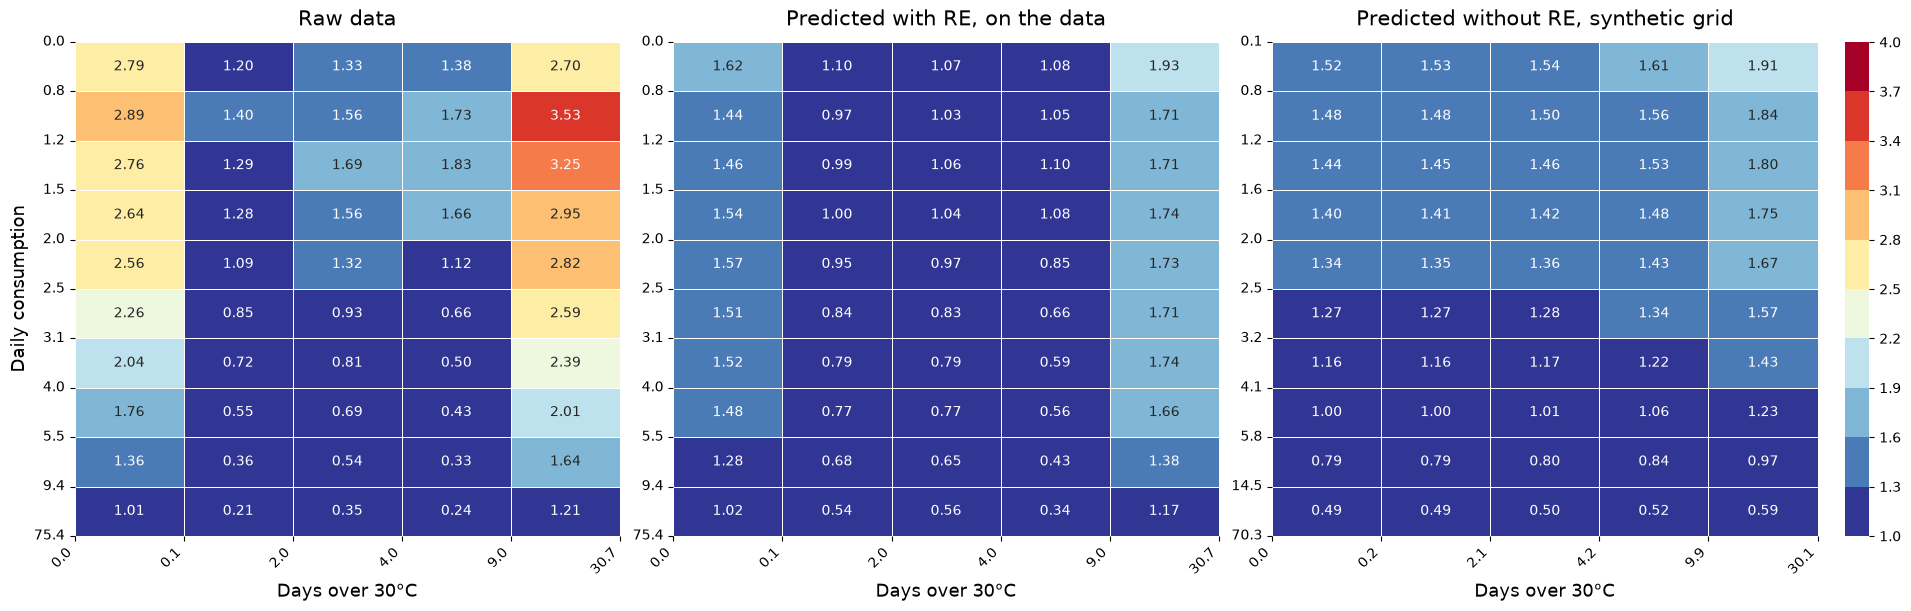


Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/child_mortality_three_panel.png
  Raw data                               range 0.21-3.53  income wrong-way 7/45, heat wrong-way 16/40
  Predicted with RE, on the data         range 0.34-1.93  income wrong-way 10/45, heat wrong-way 21/40
  Predicted without RE, synthetic grid   range 0.49-1.91  income wrong-way 0/45, heat wrong-way 0/40


In [11]:
# Child mortality, three panels: data | model on the data | model on a grid ###
#
# Left    what actually happened to these children
# Middle  what the model says about THOSE SAME children, random effects included
# Right   what the model says about hypothetical children, everything but the
#         two axes held still, random effects excluded
#
# Reading left to right you move from observation, to the model's account of
# the observations, to the model's shape with the confounding stripped out.
#
# Why there is no max-age reduction here
# --------------------------------------
# Cell 6 reduces each child to their oldest row and divides by `age_month`,
# because that is what the published 2026-05-08 figure does. It cannot be done
# on the right-hand panel - a synthetic grid has no children to reduce and no
# ages to take the maximum of. Mixing the two would put the panels on different
# denominators (they differ by 8.3% on this extract: 145,015,190 person-months
# under max-age against 158,134,417 under interval widths), so all three panels
# here use the SAME convention: every row counts, and each contributes the
# WIDTH of its age interval - 1, 2, 3, 6, 12, 12, 12, 12 months.
#
# How the two models are combined
# -------------------------------
# The neonatal fit supplies the [0, 1) month interval, the 5q28 fit the seven
# from [1, 3) to [48, 60). Together they span 0-60 months, so the stack is 5q0.
# In person-time form the identity 5q0 = 1 - (1 - 28q0)(1 - 5q28) becomes simple
# addition: deaths and months at risk are each summed, then divided.
#
# The formula, the same for every panel
# -------------------------------------
#     rate = 1000 * (sum of deaths or predicted probabilities)
#                 / (sum of age-interval widths)
#
# Left takes real deaths, middle the with-RE predictions on the observed rows,
# right the without-RE predictions on the lattice.
#
# One asymmetry to keep in mind: in the two left panels a cell is weighted by
# how many children actually fall in it; on the grid every lattice point counts
# the same, so a combination almost nobody experiences carries equal weight.
P3_DUR = {
    "age_1_m": 1,
    "age_3_m": 2,
    "age_6_m": 3,
    "age_12_m": 6,
    "age_24_m": 12,
    "age_36_m": 12,
    "age_48_m": 12,
    "age_60_m": 12,
}
P3_X, P3_Y = "days_over_30C", "consumption_pd"
P3_X_BINS = [0, 0.1, 2, 4, 9, 31]
P3_Y_BINS = [
    0,
    0.784781,
    1.180789,
    1.541445,
    1.950251,
    2.465952,
    3.103463,
    4.003564,
    5.541124,
    9.413681,
    112.879922,
]
P3_MULT, P3_VMIN, P3_VMAX = 1000, 1.0, 4.0
P3_RECALL = 120
P3_RENAME = {
    "neonatal": {"days_over_30C_prev_0_mo": P3_X, "consumption_pd": P3_Y},
    "child": {"days_over_30C_monthly_cumul": P3_X, "consumption_pd_cumul": P3_Y},
}
P3_OUT = f"{PLOT_OUTPUT}child_mortality_three_panel.png"

_avg_nn = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
_avg_cm = Path(TRAINING_5q28_PATH) / "base_model_avg_covariate_predictions.parquet"
_grid_f = Path(TRAINING_5q28_PATH) / "synthetic_grid_combined.parquet"
for _p in (_avg_nn, _avg_cm, _grid_f):
    if not _p.exists():
        raise FileNotFoundError(
            f"{_p} not found; build it in the cluster-dev env first."
        )


def _p3_cells(frame, value_col, dur_col):
    f = frame.copy()
    f["_x"] = pd.cut(f[P3_X], bins=P3_X_BINS, include_lowest=True, right=False)
    f["_y"] = pd.cut(f[P3_Y], bins=P3_Y_BINS, include_lowest=True, right=False)
    f = f[f[["_x", "_y"]].notna().all(axis=1)]
    num = f.groupby(["_y", "_x"], observed=False)[value_col].sum().unstack()
    den = f.groupby(["_y", "_x"], observed=False)[dur_col].sum().unstack()
    return (num / den) * P3_MULT, f


# ---- left: the observed outcome, all eight intervals ----------------------
_d = pd.read_parquet(
    RAW_DATA_5q0_PATH,
    columns=[
        "days_over_30C_monthly_cumul",
        "consumption_pd_cumul",
        "age_group",
        "child_mortality",
        "int_birth_year_diff_months",
    ],
).rename(columns=P3_RENAME["child"])
_d = _d[_d["int_birth_year_diff_months"] <= P3_RECALL]
_d["dur"] = _d["age_group"].astype(str).map(P3_DUR)
if _d["dur"].isna().any():
    raise ValueError("age_group values outside P3_DUR")

# ---- middle: with-RE predictions on those same rows, both models stacked ---
_nn = pd.read_parquet(_avg_nn).rename(columns=P3_RENAME["neonatal"])
_nn["dur"] = P3_DUR["age_1_m"]
_cm = pd.read_parquet(_avg_cm).rename(columns=P3_RENAME["child"])
_dummies = [c for c in _cm.columns if c in P3_DUR]
_ref = [a for a in P3_DUR if a not in _dummies and a != "age_1_m"]
if len(_ref) != 1:
    raise ValueError(f"expected one reference stratum, got {_ref}")
_hit = _cm[_dummies].astype(int).to_numpy()
_cm["dur"] = np.where(
    _hit.sum(axis=1) == 0,
    P3_DUR[_ref[0]],
    np.array([P3_DUR[c] for c in _dummies])[_hit.argmax(axis=1)],
)
_mid = pd.concat(
    [_nn[[P3_X, P3_Y, "dur", "avg_fits"]], _cm[[P3_X, P3_Y, "dur", "avg_fits"]]],
    ignore_index=True,
)

# ---- right: the synthetic lattice -----------------------------------------
_gr = pd.read_parquet(_grid_f).rename(columns={"_dur": "dur"})

_mats, _frames = {}, {}
_mats["data"], _frames["data"] = _p3_cells(_d, "child_mortality", "dur")
_mats["me"], _frames["me"] = _p3_cells(_mid, "avg_fits", "dur")
_mats["grid"], _frames["grid"] = _p3_cells(_gr, "pred_fe", "dur")

P3_PANELS = [
    ("data", "Raw data"),
    ("me", "Predicted with RE, on the data"),
    ("grid", "Predicted without RE, synthetic grid"),
]
print(
    f"left   {len(_frames['data']):,} child-interval rows, "
    f"{_frames['data']['dur'].sum():,.0f} person-months"
)
print(
    f"middle {len(_frames['me']):,} rows ({len(_nn):,} neonatal + {len(_cm):,} 5q28), "
    f"reference stratum {_ref[0]}"
)
print(
    f"right  {len(_frames['grid']):,} lattice rows, "
    f"{_frames['grid'][P3_X].nunique()} x {_frames['grid'][P3_Y].nunique()} points "
    f"x {_gr['_stratum'].nunique()} intervals"
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6), constrained_layout=True)
_b = np.linspace(P3_VMIN, P3_VMAX, 11)
_cmap = plt.get_cmap("RdYlBu_r", len(_b) - 1)
_norm = mcolors.BoundaryNorm(_b, _cmap.N, clip=True)
for ax, (k, label) in zip(axes, P3_PANELS):
    m = _mats[k]
    sns.heatmap(
        m,
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 10, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=P3_VMIN,
        vmax=P3_VMAX,
        cbar=(k == P3_PANELS[-1][0]),
        cbar_kws={"ticks": _b},
        linewidths=0.5,
        linecolor="white",
    )
    xl = _frames[k].groupby("_x", observed=False)[P3_X].min().tolist() + [
        float(_frames[k][P3_X].max())
    ]
    yl = _frames[k].groupby("_y", observed=False)[P3_Y].min().tolist() + [
        float(_frames[k][P3_Y].max())
    ]
    ax.set_title(label, fontsize=15, pad=12)
    ax.set_xticks(np.arange(m.shape[1] + 1))
    ax.set_yticks(np.arange(m.shape[0] + 1))
    ax.set_xticklabels([f"{v:.1f}" for v in xl], rotation=45, ha="right", fontsize=10)
    ax.set_yticklabels([f"{v:.1f}" for v in yl], rotation=0, fontsize=10)
    ax.set_xlabel("Days over 30°C", fontsize=13)
    ax.set_ylabel("Daily consumption" if ax is axes[0] else "", fontsize=13)
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=10)
        ax.collections[0].colorbar.ax.yaxis.set_major_formatter(
            mticker.FormatStrFormatter("%.1f")
        )
fig.savefig(P3_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nSaved {P3_OUT}")
for k, label in P3_PANELS:
    v = _mats[k].to_numpy()
    dy, dx = np.diff(v, axis=0), np.diff(v, axis=1)
    print(
        f"  {label:38s} range {np.nanmin(v):.2f}-{np.nanmax(v):.2f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )

In [12]:
# How the residual model works, one page per super region ####################
#
# What the residual model is
# --------------------------
# After inference the pipeline compares the model against GBD over the years
# GBD covers, and fits the gap:
#
#     residual_value = gbd_value - model_value
#
# to SDI, with this formula (run_residual.get_residual_prediction):
#
#     residual_value ~ 0 + sdi:C(super_region_name) + C(location_age_sex)
#
# So yes - the SDI SLOPES are per super region, seven of them. The INTERCEPTS
# are not: there is one per location-age-sex cell, 946 of them here. The `0 +`
# and the pure interaction matter - with no main `sdi` term patsy uses full
# dummy coding, so every super region gets a standalone slope and none is a
# reference level.
#
# Afterwards ENFORCE_NON_POSITIVE_SDI_SLOPES clips any positive slope to zero,
# on the view that the model should not get worse relative to GBD as a country
# develops. Both the raw and clipped slopes are shown below.
#
# Why the fit has to be refitted here
# -----------------------------------
# The residual step fits this in memory, prints the summary and keeps only the
# predictions - no coefficients are written to disk. Everything needed to
# reproduce it is saved though, so the cell refits the same formula on the same
# inputs and checks the result against `residual_model_value` in sev_means.
#
# Why the y axis is a PARTIAL residual
# ------------------------------------
# A fitted value is slope(super_region) * sdi + intercept(location_age_sex).
# With 946 intercepts there is no single line per super region to draw against
# the raw residuals - each region is a sheaf of 100-odd parallel lines. So the
# intercept is subtracted from each point:
#
#     partial residual = residual_value - intercept(location_age_sex)
#
# and then each super region's fit IS one line through the origin with that
# region's slope. This is the standard way to see a slope from a model carrying
# many intercepts; it changes the vertical position of the points, not the
# slope being illustrated.
# Nothing is imported from rra_climate_health here. The residual step lives in
# the rra-climate-health_2 clone and this notebook's kernel has the other one,
# where `rra_climate_health.residual` does not exist. The two pieces it needs
# are small enough to restate: the slope clip, and SDI.
LAST_GBD_YEAR = 2023  # constants.LAST_GBD_YEAR
ENFORCE_NON_POSITIVE_SDI_SLOPES = True  # run_residual module flag


def adjust_sdi_slopes_non_positive(coefficients, exog_names, levels):
    """Clip any positive SDI slope to zero, one super region at a time.

    Restated from run_residual.adjust_sdi_slopes_non_positive. Because the
    formula uses `sdi:C(super_region_name)` with no main sdi term, each region
    owns a standalone coefficient and clipping one cannot move another.
    """
    out = coefficients.copy()
    pat = re.compile(r"^sdi:C\(super_region_name\)\[(?:T\.)?(.*)\]$")
    terms = {m.group(1): t for t in exog_names for m in [pat.match(t)] if m}
    if not terms:
        print("Warning: no sdi:C(super_region_name)[...] terms; nothing clipped.")
        return out
    missing = [lv for lv in levels if lv not in terms]
    if missing:
        print(f"Warning: no slope term for {missing}")
    if "sdi" in out.index:
        print("Warning: a bare 'sdi' term is present; slopes are shared.")
    n = 0
    for level, term in sorted(terms.items()):
        slope = float(out[term])
        if slope > 0:
            print(f"  {level}: slope {slope:+.4f} is positive -> 0.0")
            out[term] = 0.0
            n += 1
        else:
            print(f"  {level}: slope {slope:+.4f} is not positive, left as fitted")
    print(
        f"Clipped {n} of {len(terms)} super-region SDI slopes; "
        f"the other {len(terms) - n} are unchanged."
    )
    return out


# SDI comes from a cached parquet rather than the source netCDFs. The round-38
# files are zstd-compressed and most environments here have no HDF5 zstd
# plugin, so reading them from this kernel fails with "undefined filter
# encountered". The cache is the draw-mean of past + future at the reference
# scenario - exactly what residual_data.get_sdi returns.
SDI_CACHE = (
    "/mnt/team/rapidresponse/pub/population/modeling/"
    "climate_malnutrition/input/sdi_cache_s159v8.parquet"
)


def get_sdi():
    if not Path(SDI_CACHE).exists():
        raise FileNotFoundError(
            f"{SDI_CACHE} not found. Rebuild it from an environment with an "
            "HDF5 zstd plugin:\n"
            "    from rra_climate_health.residual.residual_data import get_sdi\n"
            f"    get_sdi().to_parquet('{SDI_CACHE}', index=False)"
        )
    return pd.read_parquet(SDI_CACHE)


RES_DIR = Path(RESULTS_5q28_PATH).parent
RES_OUT = f"{PLOT_OUTPUT}child_mortality_residual_by_super_region.pdf"
RES_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/"

_sev = pd.read_parquet(RES_DIR / "sev_means.parquet").reset_index()
_hier = pd.read_parquet(RES_ROOT + "input/fhs_hierarchy.parquet")

_fit_df = _sev.dropna(subset=["gbd_value", "model_value"]).copy()
_fit_df = _fit_df[_fit_df["year_id"] <= LAST_GBD_YEAR]
_fit_df["residual_value"] = _fit_df["gbd_value"] - _fit_df["model_value"]
_fit_df = _fit_df.merge(get_sdi(), on=["location_id", "year_id"], how="left")
_fit_df = _fit_df.merge(
    _hier[["location_id", "super_region_name"]].drop_duplicates("location_id"),
    on="location_id",
    how="left",
)
_fit_df["location_age_sex"] = (
    _fit_df.location_id.astype(str)
    + "_"
    + _fit_df.age_group_id.astype(str)
    + "_"
    + _fit_df.sex_id.astype(str)
)
_before = len(_fit_df)
_fit_df = _fit_df.dropna(subset=["sdi", "super_region_name"])
print(
    f"fitting on {len(_fit_df):,} rows "
    f"({_before - len(_fit_df):,} dropped for missing sdi or super region), "
    f"{_fit_df.location_age_sex.nunique():,} location-age-sex cells, "
    f"{_fit_df.super_region_name.nunique()} super regions, "
    f"years {int(_fit_df.year_id.min())}-{int(_fit_df.year_id.max())}"
)

_fit = smf.ols(
    "residual_value ~ 0 + sdi:C(super_region_name) + C(location_age_sex)", data=_fit_df
).fit()

# pull the slopes out, raw and after the non-positive clip
# full dummy coding, so the level sits in plain brackets: `sdi:C(...)[Name]`,
# not the `[T.Name]` that treatment coding would give
_slope_terms = {
    t: t[t.index("[") + 1 : -1] for t in _fit.params.index if t.startswith("sdi:C(")
}
RES_SLOPES = pd.DataFrame(
    {
        "super_region_name": list(_slope_terms.values()),
        "slope_raw": [_fit.params[t] for t in _slope_terms],
    }
)
if ENFORCE_NON_POSITIVE_SDI_SLOPES:
    _adj = adjust_sdi_slopes_non_positive(
        _fit.params, _fit.model.exog_names, _fit_df["super_region_name"].unique()
    )
    RES_SLOPES["slope_used"] = [_adj[t] for t in _slope_terms]
else:
    RES_SLOPES["slope_used"] = RES_SLOPES["slope_raw"]
RES_SLOPES = RES_SLOPES.sort_values("slope_used").reset_index(drop=True)
print("\nSDI slopes (residual per unit SDI, prevalence units):")
print(RES_SLOPES.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print(f"\nR-squared {_fit.rsquared:.4f}   n {int(_fit.nobs):,}")

# intercept per location-age-sex, then the partial residual
_icpt = {
    t[t.index("[") + 1 : -1]: v
    for t, v in _fit.params.items()
    if t.startswith("C(location_age_sex)")
}
_fit_df["intercept"] = _fit_df["location_age_sex"].map(_icpt)
if _fit_df["intercept"].isna().any():
    raise ValueError("a location-age-sex cell has no intercept coefficient")
_fit_df["partial_residual"] = _fit_df["residual_value"] - _fit_df["intercept"]

# check the refit against what the pipeline actually wrote
_chk = _sev.dropna(subset=["residual_model_value", "model_value"]).copy()
_chk = _chk[_chk.year_id <= LAST_GBD_YEAR]
_chk["implied"] = _chk["residual_model_value"] - _chk["model_value"]
print(
    f"\nsanity: pipeline's residual_model_value - model_value spans "
    f"{_chk['implied'].min():+.5f} to {_chk['implied'].max():+.5f}; "
    f"our fitted residuals span "
    f"{_fit.fittedvalues.min():+.5f} to {_fit.fittedvalues.max():+.5f}"
)

RES_ORDER = RES_SLOPES.super_region_name.tolist()
RES_COLORS = dict(
    zip(
        RES_ORDER,
        ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"][
            : len(RES_ORDER)
        ],
    )
)
_xs = np.linspace(_fit_df.sdi.min(), _fit_df.sdi.max(), 50)

with PdfPages(RES_OUT) as pdf:
    for sr in RES_ORDER:
        fig, ax = plt.subplots(figsize=(10, 6.5))
        # every point, every page
        ax.scatter(
            _fit_df.sdi,
            _fit_df.partial_residual,
            s=3,
            c="#c3c2b7",
            alpha=0.35,
            linewidths=0,
            zorder=1,
            label="all super regions",
        )
        _m = _fit_df.super_region_name == sr
        ax.scatter(
            _fit_df.sdi[_m],
            _fit_df.partial_residual[_m],
            s=5,
            c=RES_COLORS[sr],
            alpha=0.75,
            linewidths=0,
            zorder=3,
            label=sr,
        )
        # every fit, every page
        for other in RES_ORDER:
            s_ = float(
                RES_SLOPES.loc[
                    RES_SLOPES.super_region_name == other, "slope_used"
                ].iloc[0]
            )
            ax.plot(
                _xs,
                s_ * _xs,
                color=RES_COLORS[other],
                lw=3 if other == sr else 1.2,
                alpha=1.0 if other == sr else 0.45,
                zorder=5 if other == sr else 4,
            )
        _row = RES_SLOPES[RES_SLOPES.super_region_name == sr].iloc[0]
        _clipped = (
            " (clipped to 0 from %+.4f)" % _row.slope_raw
            if abs(_row.slope_used - _row.slope_raw) > 1e-12
            else ""
        )
        ax.axhline(0, color="#898781", lw=0.8, ls=":")
        ax.set_title(
            f"{sr}\nSDI slope {_row.slope_used:+.4f}{_clipped}"
            f"   n = {int(_m.sum()):,} of {len(_fit_df):,}",
            fontsize=13,
        )
        ax.set_xlabel("SDI", fontsize=12)
        ax.set_ylabel("Residual, location-age-sex intercept removed", fontsize=12)
        ax.grid(True, ls="--", lw=0.5, alpha=0.5)
        ax.legend(loc="upper right", fontsize=9, markerscale=3, framealpha=0.9)
        fig.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)
print(f"\nSaved {RES_OUT} ({len(RES_ORDER)} pages, one per super region)")

fitting on 22,704 rows (0 dropped for missing sdi or super region), 946 location-age-sex cells, 7 super regions, years 2000-2023
  Central Europe, Eastern Europe, and Central Asia: slope +0.1247 is positive -> 0.0
  High-income: slope -0.0199 is not positive, left as fitted
  Latin America and Caribbean: slope -0.0348 is not positive, left as fitted
  North Africa and Middle East: slope -0.0692 is not positive, left as fitted
  South Asia: slope +0.0022 is positive -> 0.0
  Southeast Asia, East Asia, and Oceania: slope +0.0895 is positive -> 0.0
  Sub-Saharan Africa: slope -0.1553 is not positive, left as fitted
Clipped 3 of 7 super-region SDI slopes; the other 4 are unchanged.

SDI slopes (residual per unit SDI, prevalence units):
                               super_region_name  slope_raw  slope_used
                              Sub-Saharan Africa    -0.1553     -0.1553
                    North Africa and Middle East    -0.0692     -0.0692
                     Latin America and Car

In [ ]:
# Child mortality, three panels, expressed as 5q0 ############################
#
# Same three panels, same rows, same bins and same recall window as the
# person-time figure above. The ONLY thing that changes is the statistic in
# each cell.
#
# Left    what actually happened to these children
# Middle  what the model says about THOSE SAME children, random effects included
# Right   what the model says about hypothetical children, everything but the
#         two axes held still, random effects excluded
#
# What the number in each cell now means
# --------------------------------------
# Deaths per 1000 live births before the fifth birthday - 5q0 - instead of
# deaths per 1000 person-months. It is a probability over a fixed five-year
# window, so it needs no denominator in time and is directly comparable to a
# published under-5 mortality rate.
#
# Why it is NOT the person-time rate times sixty
# ----------------------------------------------
# A rate converts to a probability only under a constant hazard, and the
# hazard here is anything but constant: the conditional probability of dying
# runs 0.0294 in the first month against 0.0028 in the fifth year, a factor of
# ten. Multiplying out a blended rate would therefore be wrong in both tails.
#
# The life-table construction instead
# -----------------------------------
# Each row of every panel already belongs to exactly one of the eight age
# intervals. Within a cell, take the conditional probability of dying in each
# interval separately,
#
#     q_a  =  deaths in interval a in this cell / children at risk in a in this cell
#
# and chain the eight survivals together:
#
#     5q0  =  1 - PRODUCT over a of (1 - q_a)
#
# This is the same identity the pipeline uses to join the two fits,
# 5q0 = 1 - (1 - 28q0)(1 - 5q28), carried out over all eight intervals rather
# than two. It is exact, not an approximation, and the interval WIDTHS that
# the person-time version needed as a denominator drop out entirely - the
# length of each interval is already baked into its own q_a.
#
# How to read a cell
# ------------------
# A synthetic cohort: the probability of dying before five for a child who
# experienced THIS (heat, income) combination through all five years. No real
# child does that - the cumulative covariates move as a child ages, so one
# child contributes rows to several cells - which is exactly why the synthetic
# reading is the useful one.
#
# Denominators are clean on this extract
# --------------------------------------
# The chained product is sensitive to the at-risk count in each interval in a
# way the pooled rate is not, so this was checked: on 2026_10_07.01 within the
# 120-month recall window, not one child has a row after the interval in which
# they died. Truncating post-death rows drops 0 of 23,515,189 rows and moves
# 5q0 by 0.00. (The old 2026_04_28.01 extract DID carry deaths forward; this
# one does not.) Every denominator here is therefore a true at-risk count.
#
# Where the model sits
# --------------------
# The neonatal fit supplies the [0, 1) month interval, the 5q28 fit the seven
# from [1, 3) to [48, 60). Together they span 0-60 months, so the stack is 5q0.
Q5_STRATA = [
    "age_1_m",
    "age_3_m",
    "age_6_m",
    "age_12_m",
    "age_24_m",
    "age_36_m",
    "age_48_m",
    "age_60_m",
]
Q5_X, Q5_Y = "days_over_30C", "consumption_pd"
Q5_X_BINS = [0, 0.1, 2, 4, 9, 31]
Q5_Y_BINS = [
    0,
    0.784781,
    1.180789,
    1.541445,
    1.950251,
    2.465952,
    3.103463,
    4.003564,
    5.541124,
    9.413681,
    112.879922,
]
# per 1000 live births; the three panels share one scale so the model's
# narrower spread against the data is visible rather than hidden
Q5_MULT, Q5_VMIN, Q5_VMAX = 1000, 20.0, 170.0
# Same size and type as the neonatal figure above, so the two drop into the
# same 12.6 x 4.2in deck slot and can be read side by side. Everything that
# names the figure is stripped - no panel titles, no axis labels, no colourbar
# label - so the panels can be captioned wherever they land.
Q5_FIGSIZE, Q5_TICK_SIZE, Q5_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
Q5_RECALL = 120
Q5_RENAME = {
    "neonatal": {"days_over_30C_prev_0_mo": Q5_X, "consumption_pd": Q5_Y},
    "child": {"days_over_30C_monthly_cumul": Q5_X, "consumption_pd_cumul": Q5_Y},
}
Q5_OUT = f"{PLOT_OUTPUT}child_mortality_three_panel_5q0.png"

_q5_avg_nn = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
_q5_avg_cm = Path(TRAINING_5q28_PATH) / "base_model_avg_covariate_predictions.parquet"
_q5_grid_f = Path(TRAINING_5q28_PATH) / "synthetic_grid_combined.parquet"
for _p in (_q5_avg_nn, _q5_avg_cm, _q5_grid_f):
    if not _p.exists():
        raise FileNotFoundError(
            f"{_p} not found; build it in the cluster-dev env first."
        )


def _q5_cells(frame, value_col):
    """Per-cell 5q0 from the eight interval-specific conditional probabilities.

    `value_col` is a death indicator on the data panel and a predicted
    probability on the two model panels; in both cases its MEAN within an
    (cell, interval) group is that interval's conditional probability q_a.
    A cell missing any of the eight intervals is left NaN rather than chained
    over a shorter life table.
    """
    f = frame.copy()
    f["_x"] = pd.cut(f[Q5_X], bins=Q5_X_BINS, include_lowest=True, right=False)
    f["_y"] = pd.cut(f[Q5_Y], bins=Q5_Y_BINS, include_lowest=True, right=False)
    f = f[f[["_x", "_y"]].notna().all(axis=1)]
    g = f.groupby(["_y", "_x", "_stratum"], observed=False)[value_col]
    surv = (1.0 - g.mean()).unstack("_stratum")
    n_min = int(g.size().min())
    q5 = (1.0 - surv.prod(axis=1, skipna=False)).unstack("_x") * Q5_MULT
    return q5, f, int(surv.isna().sum().sum()), n_min


# ---- left: the observed outcome, all eight intervals ----------------------
_q5_d = pd.read_parquet(
    RAW_DATA_5q0_PATH,
    columns=[
        "days_over_30C_monthly_cumul",
        "consumption_pd_cumul",
        "age_group",
        "child_mortality",
        "int_birth_year_diff_months",
    ],
).rename(columns=Q5_RENAME["child"])
_q5_d = _q5_d[_q5_d["int_birth_year_diff_months"] <= Q5_RECALL]
_q5_d["_stratum"] = _q5_d["age_group"].astype(str)
if set(_q5_d["_stratum"]) != set(Q5_STRATA):
    raise ValueError(f"unexpected age_group values: {sorted(set(_q5_d['_stratum']))}")

# ---- middle: with-RE predictions on those same rows, both models stacked ---
_q5_nn = pd.read_parquet(_q5_avg_nn).rename(columns=Q5_RENAME["neonatal"])
_q5_nn["_stratum"] = "age_1_m"
_q5_cm = pd.read_parquet(_q5_avg_cm).rename(columns=Q5_RENAME["child"])
_q5_dum = [c for c in _q5_cm.columns if c in Q5_STRATA]
_q5_ref = [a for a in Q5_STRATA if a not in _q5_dum and a != "age_1_m"]
if len(_q5_ref) != 1:
    raise ValueError(f"expected one reference stratum, got {_q5_ref}")
_q5_hit = _q5_cm[_q5_dum].astype(int).to_numpy()
_q5_cm["_stratum"] = np.where(
    _q5_hit.sum(axis=1) == 0,
    _q5_ref[0],
    np.array(_q5_dum)[_q5_hit.argmax(axis=1)],
)
_q5_mid = pd.concat(
    [
        _q5_nn[[Q5_X, Q5_Y, "_stratum", "avg_fits"]],
        _q5_cm[[Q5_X, Q5_Y, "_stratum", "avg_fits"]],
    ],
    ignore_index=True,
)

# ---- right: the synthetic lattice -----------------------------------------
_q5_gr = pd.read_parquet(_q5_grid_f)

_q5_mats, _q5_frames, _q5_diag = {}, {}, {}
for _k, _frm, _col in [
    ("data", _q5_d, "child_mortality"),
    ("me", _q5_mid, "avg_fits"),
    ("grid", _q5_gr, "pred_fe"),
]:
    _q5_mats[_k], _q5_frames[_k], _miss, _nmin = _q5_cells(_frm, _col)
    _q5_diag[_k] = (_miss, _nmin)

Q5_PANELS = [
    ("data", "Raw data"),
    ("me", "Predicted with RE, on the data"),
    ("grid", "Predicted without RE, synthetic grid"),
]
for _k, _label in Q5_PANELS:
    _miss, _nmin = _q5_diag[_k]
    print(
        f"{_label:38s} {len(_q5_frames[_k]):>12,} rows, "
        f"smallest (cell, interval) group {_nmin:,}, "
        f"incomplete life tables {_miss}"
    )
_q5_pool = _q5_d.groupby("_stratum")["child_mortality"].mean().reindex(Q5_STRATA)
print(
    f"\npooled 5q0 across the whole extract: "
    f"{Q5_MULT * (1 - np.prod(1 - _q5_pool.to_numpy())):.1f} per 1000"
)

# One set of tick labels for all three panels: the axis means the same thing
# everywhere, and the synthetic lattice has minima of its own (it starts at 0.1
# days and tops out at 70.3) that would otherwise put three different axes side
# by side.
#
# The income axis is labelled with the BIN EDGES, matching the neonatal figure
# so the two can sit together with the same 112.9 at the foot. Because the ten
# income bins are the data's own deciles, the edges and the smallest value
# observed in each bin agree to the first decimal for every label but the last;
# the difference is only at the top, where the edge is 112.9 and the richest
# child in the CHILD extract is 75.4.
#
# The heat axis keeps the observed-minimum convention from the earlier child
# figures, where the first column is a zero-exposure column and its label has
# to read 0.0.
_q5_ref_frame = _q5_frames["data"]
Q5_XTICKS = _q5_ref_frame.groupby("_x", observed=False)[Q5_X].min().tolist() + [
    float(_q5_ref_frame[Q5_X].max())
]
Q5_YTICKS = list(Q5_Y_BINS)

fig, axes = plt.subplots(1, 3, figsize=Q5_FIGSIZE, constrained_layout=True)
_q5_b = np.linspace(Q5_VMIN, Q5_VMAX, 11)
_q5_cmap = plt.get_cmap("RdYlBu_r", len(_q5_b) - 1)
_q5_norm = mcolors.BoundaryNorm(_q5_b, _q5_cmap.N, clip=True)
for ax, (k, label) in zip(axes, Q5_PANELS):
    m = _q5_mats[k]
    sns.heatmap(
        m,
        ax=ax,
        annot=True,
        fmt=".0f",
        annot_kws={"size": Q5_ANNOT_SIZE, "weight": "regular"},
        cmap=_q5_cmap,
        norm=_q5_norm,
        vmin=Q5_VMIN,
        vmax=Q5_VMAX,
        cbar=(k == Q5_PANELS[-1][0]),
        cbar_kws={"ticks": _q5_b},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(np.arange(m.shape[1] + 1))
    ax.set_yticks(np.arange(m.shape[0] + 1))
    ax.set_xticklabels(
        [f"{v:.1f}" for v in Q5_XTICKS], rotation=45, ha="right", fontsize=Q5_TICK_SIZE
    )
    ax.set_yticklabels(
        [f"{v:.1f}" for v in Q5_YTICKS], rotation=0, fontsize=Q5_TICK_SIZE
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        cb = ax.collections[0].colorbar
        cb.ax.tick_params(labelsize=Q5_TICK_SIZE)
        cb.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f"))
fig.savefig(Q5_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nSaved {Q5_OUT}")
for k, label in Q5_PANELS:
    v = _q5_mats[k].to_numpy()
    dy, dx = np.diff(v, axis=0), np.diff(v, axis=1)
    print(
        f"  {label:38s} range {np.nanmin(v):6.1f}-{np.nanmax(v):6.1f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )

### Low Birth Weight

lbw heatmap: 1,301,641 births, 689,506 dropped (53.0%, all zero-exposure)


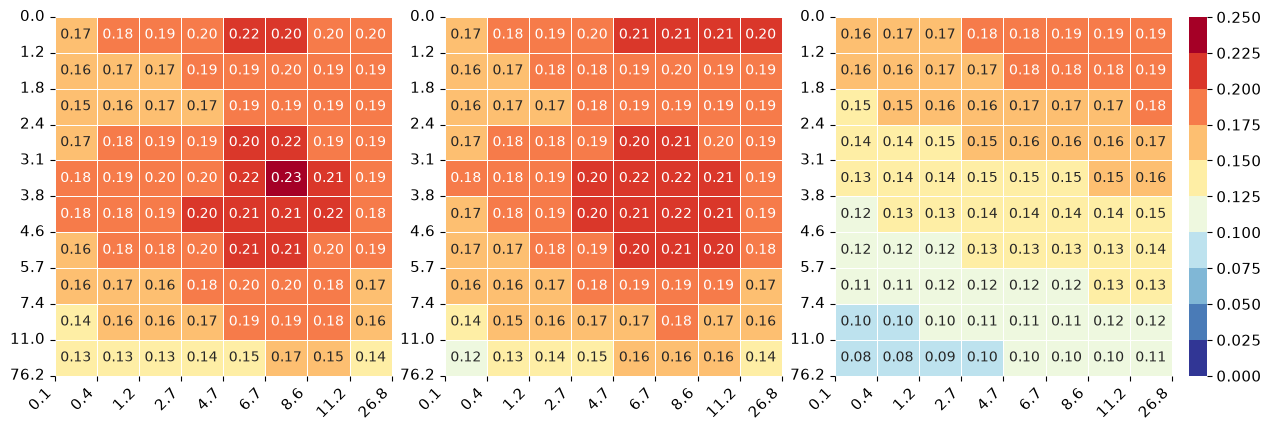

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/lbw_heatmaps.png

x bin edges ['0.1', '0.4', '1.2', '2.7', '4.7', '6.7', '8.6', '11.2', '26.8']
y bin edges ['0.0', '1.2', '1.8', '2.4', '3.1', '3.8', '4.6', '5.7', '7.4', '11.0', '76.2']
smallest cell n = 3,229
  Data                             range 0.13-0.23  income wrong-way 23/72, heat wrong-way 22/70
  With location random effects     range 0.12-0.22  income wrong-way 18/72, heat wrong-way 19/70
  Without location random effects  range 0.08-0.19  income wrong-way 0/72, heat wrong-way 0/70


In [2]:
# Low birthweight heatmaps, the pipeline's figure restyled for the deck ######
#
# A rebuild of
#   lbw/models/2026_10_16.04/heatmap_comparison.png
# which training.training_diagnostics.plot_model_heatmaps writes at the end of
# a training run. Everything that decides a NUMBER is copied from that function
# so the cells match the pipeline's figure exactly; everything that decides how
# it LOOKS is replaced with the settings the neonatal and child mortality
# figures above use, so all three drop into the same deck slot.
#
# Same as the pipeline
# --------------------
#   panels      data, with location REs, without location REs
#   source      raw_with_predictions.parquet (`lbw`, `fits`, `no_re_fits`)
#   x bins      8 QUANTILES of days_over_30C_past_9m among rows with exposure
#               above zero. Zero-exposure pregnancies are dropped, not given a
#               column of their own - that is the lbw branch of the function,
#               and it is why the axis starts at 0.1 rather than 0.0.
#   y bins      10 quantiles of ldi_pc_pd
#   tick labels the BIN EDGES at one decimal, as the pipeline prints them
#   scale       0 to 0.25 prevalence in ten bands, RdYlBu_r
#   annotations two decimals - prevalence here runs 0.08 to 0.23, so one
#               decimal would collapse most of the figure to 0.1 or 0.2
#
# Changed for the deck
# --------------------
#   no panel titles, no axis labels, no colourbar label
#   tick labels and annotations at the neonatal figure's sizes
#   12.6 x 4.2in, the same slot as the other two figures
#
# Note the quantile bins are recomputed here from the same file the pipeline
# read, so they reproduce rather than merely resemble it; the check below
# prints the edges and the per-panel ranges to confirm against the png.
LBW_MODEL_DIR = Path(
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/lbw/models/2026_10_16.04"
)
LBW_X = "days_over_30C_past_9m"
LBW_Y = "ldi_pc_pd"
LBW_X_Q, LBW_Y_Q = 8, 10
LBW_VMIN, LBW_VMAX = 0.0, 0.25
LBW_PANELS = [
    ("lbw", "Data"),
    ("fits", "With location random effects"),
    ("no_re_fits", "Without location random effects"),
]
LBW_FIGSIZE, LBW_TICK_SIZE, LBW_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
LBW_OUT = f"{PLOT_OUTPUT}lbw_heatmaps.png"

_lbw_file = LBW_MODEL_DIR / "raw_with_predictions.parquet"
if not _lbw_file.exists():
    raise FileNotFoundError(f"{_lbw_file} not found")
_lbw = pd.read_parquet(_lbw_file, columns=[LBW_X, LBW_Y, *[k for k, _ in LBW_PANELS]])

# the pipeline bins only the rows with exposure above zero and lets the rest
# fall out as NaN, so they never reach the heatmap
_lbw["_x"], _lbw_xb = pd.qcut(_lbw.loc[_lbw[LBW_X] > 0, LBW_X], LBW_X_Q, retbins=True)
_lbw["_y"], _lbw_yb = pd.qcut(_lbw[LBW_Y], LBW_Y_Q, retbins=True)
_lbw_kept = _lbw[["_x", "_y"]].notna().all(axis=1)
print(
    f"lbw heatmap: {len(_lbw):,} births, {int((~_lbw_kept).sum()):,} dropped "
    f"({100 * (1 - _lbw_kept.mean()):.1f}%, all zero-exposure)"
)

LBW_XTICKS = [f"{v:.1f}" for v in _lbw_xb]
LBW_YTICKS = [f"{v:.1f}" for v in _lbw_yb]
_lbw_mats = {
    k: _lbw.groupby(["_y", "_x"], observed=False)[k].mean().unstack()
    for k, _ in LBW_PANELS
}
_lbw_n = _lbw.groupby(["_y", "_x"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 3, figsize=LBW_FIGSIZE, constrained_layout=True)
_lbw_b = np.linspace(LBW_VMIN, LBW_VMAX, 11)
_lbw_cmap = plt.get_cmap("RdYlBu_r", len(_lbw_b) - 1)
_lbw_norm = mcolors.BoundaryNorm(_lbw_b, _lbw_cmap.N, clip=True)
for ax, (k, label) in zip(axes, LBW_PANELS):
    sns.heatmap(
        _lbw_mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": LBW_ANNOT_SIZE, "weight": "regular"},
        cmap=_lbw_cmap,
        norm=_lbw_norm,
        vmin=LBW_VMIN,
        vmax=LBW_VMAX,
        cbar=(k == LBW_PANELS[-1][0]),
        cbar_kws={"ticks": _lbw_b},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(LBW_XTICKS)))
    ax.set_xticklabels(LBW_XTICKS, rotation=45, ha="right", fontsize=LBW_TICK_SIZE)
    ax.set_yticks(range(len(LBW_YTICKS)))
    ax.set_yticklabels(LBW_YTICKS, rotation=0, fontsize=LBW_TICK_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=LBW_TICK_SIZE)
fig.savefig(LBW_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {LBW_OUT}")

print(f"\nx bin edges {LBW_XTICKS}")
print(f"y bin edges {LBW_YTICKS}")
print(f"smallest cell n = {int(_lbw_n.min().min()):,}")
for k, label in LBW_PANELS:
    m = _lbw_mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:32s} range {np.nanmin(m):.2f}-{np.nanmax(m):.2f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )

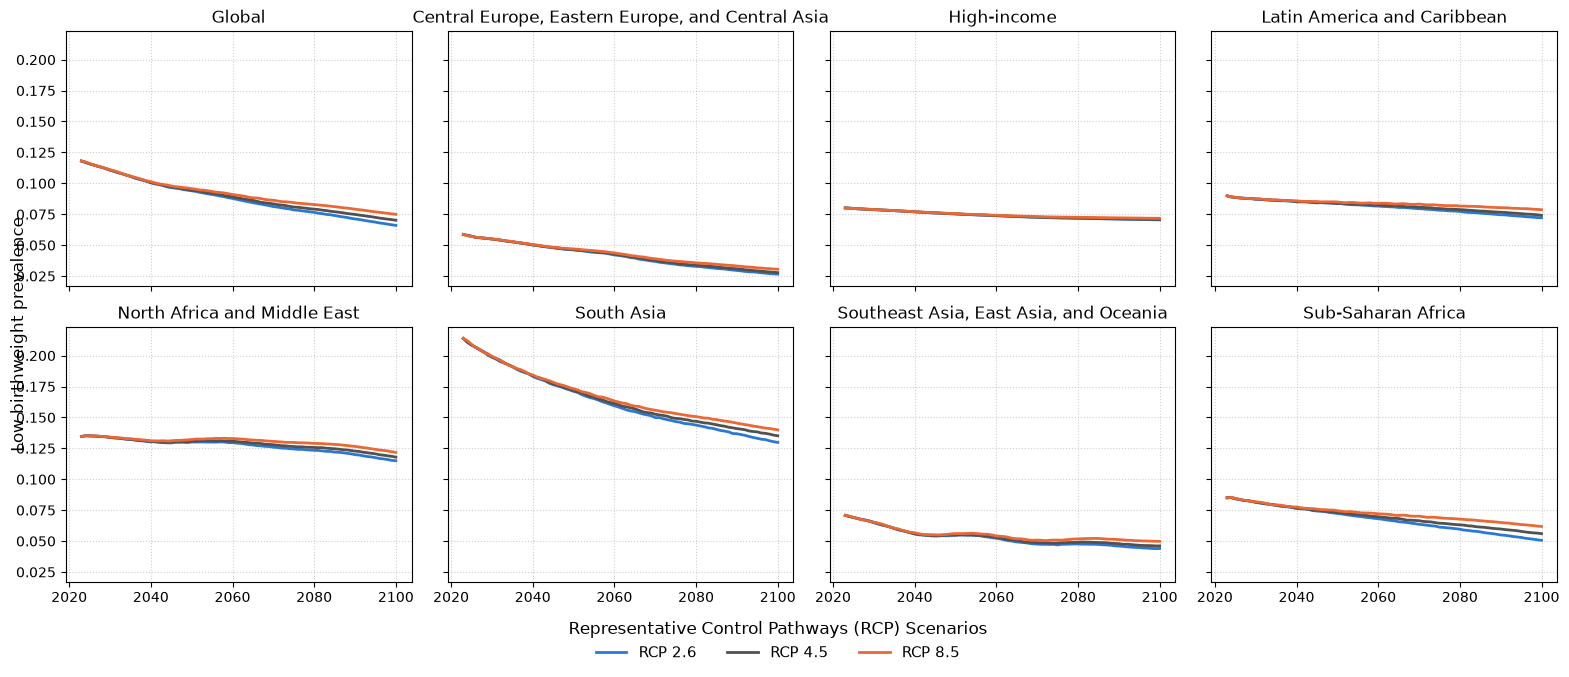

,year_id,location_name,scenario,millions
0,2050,Global,ssp245 - ssp126,0.818414
1,2050,Global,ssp585 - ssp126,2.222820
2,2050,Global,ssp585 - ssp245,1.404406
3,2050,"Central Europe, Eastern Europe, and Central Asia",ssp245 - ssp126,0.010118
4,2050,"Central Europe, Eastern Europe, and Central Asia",ssp585 - ssp126,0.032475
5,2050,"Central Europe, Eastern Europe, and Central Asia",ssp585 - ssp245,0.022357
6,2050,High-income,ssp245 - ssp126,0.002975
7,2050,High-income,ssp585 - ssp126,0.027212
8,2050,High-income,ssp585 - ssp245,0.024237
9,2050,Latin America and Caribbean,ssp245 - ssp126,0.027445


In [3]:
# LBW: scenario lines and cumulative difference table #######################
#
# The deck-format version of the two outputs the residual step makes,
# superregion_prev.pdf and table1_cumulative_case_counts.csv, built from the
# pipeline's own `shifted_prevalence.parquet`, which already holds all three
# scenarios at the most-detailed locations.
#
# Weighted by LIVE BIRTHS, not the pipeline's population. LBW is a property
# of a birth, so the number of low-birthweight babies is LBW share x births.
# The pipeline instead multiplies by the age group 2 population - babies aged
# 0-6 days alive at one moment, about one week of births - so its counts run
# ~52x low (live births / age 2 population = 52.2 in 2024; 365/7 = 52.1).
# As a check on the scale: global LBW prevalence of 11.4% in 2024 gives about
# 14.3 million low-birthweight babies on births, against 274,000 on the age 2
# population; published estimates put the real figure near 20 million.
#
# The cumulative table will therefore NOT match the pipeline's own
# table1_cumulative_case_counts.csv for this results version - by about that
# factor of 52. The line plots, which are prevalences, are essentially
# unchanged.
lbw_counts, lbw_table1, _ = scenario_outputs(
    RESULTS_LBW_PATH, LBW_YLABEL, LBW_PLOT_FILE, LBW_TABLE_FILE, weight="births"
)
plt.show()
lbw_table1

### Anemia

anemia heatmap: 3,175,520 rows, 1,152,799 dropped (36.3%, all zero-exposure)


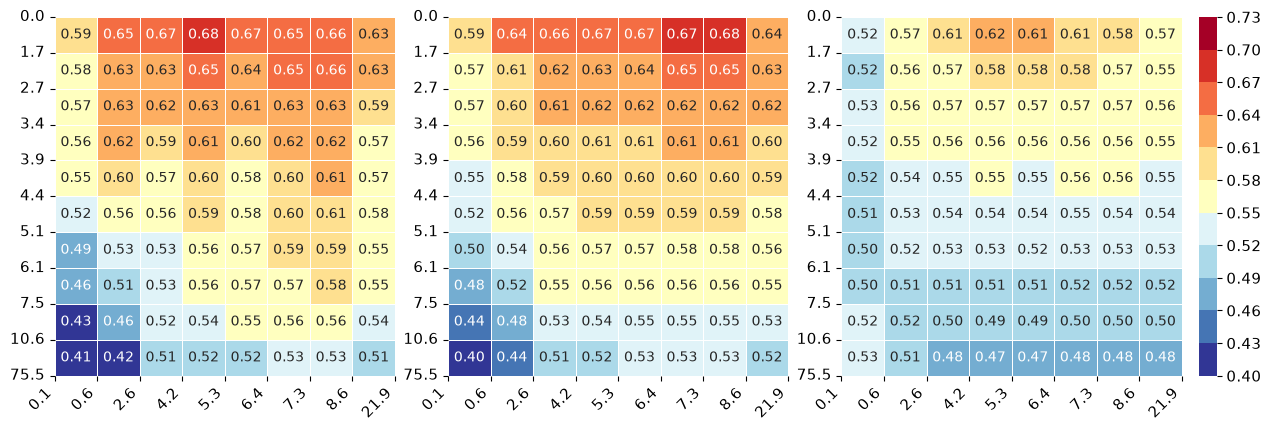

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/anemia_heatmaps.png

colour boundaries [0.4, 0.43, 0.46, 0.49, 0.52, 0.55, 0.58, 0.61, 0.64, 0.67, 0.7, 0.73]
x bin edges ['0.1', '0.6', '2.6', '4.2', '5.3', '6.4', '7.3', '8.6', '21.9']
y bin edges ['0.0', '1.7', '2.7', '3.4', '3.9', '4.4', '5.1', '6.1', '7.5', '10.6', '75.5']
smallest cell n = 10,953
  Data                             range 0.41-0.68  income wrong-way 3/72, heat wrong-way 22/70
  With location random effects     range 0.40-0.68  income wrong-way 1/72, heat wrong-way 17/70
  Without location random effects  range 0.47-0.62  income wrong-way 7/72, heat wrong-way 34/70


In [4]:
# Anemia heatmaps, the pipeline's figure restyled for the deck ###############
#
# A rebuild of
#   anemia/models/2026_10_15.01/heatmap_comparison.png
# on the same terms as the lbw cell above: the numbers are the pipeline's, the
# styling is the neonatal figure's. Anemia takes the same generic branch of
# training.training_diagnostics.plot_model_heatmaps that lbw does, so the
# binning is identical in form - 8 quantiles of the threshold variable among
# rows with exposure above zero, 10 quantiles of ldi_pc_pd, bin edges as tick
# labels - and only the variable and the colour range differ.
#
#   x           days_over_30C_past_12m (lbw uses the past-9-month version)
#   y           ldi_pc_pd, 10 quantiles
#   scale       0.40 to 0.70 prevalence
#   annotations two decimals; prevalence runs 0.40 to 0.68
#
# About the colour range
# ----------------------
# The published png's bar runs 0.40 to 0.73, which is what vmin = 0.4 produces:
# the pipeline builds its boundaries with
#     np.arange(vmin, vmax + (vmax - vmin) / 10, (vmax - vmin) / 10)
# and at vmin = 0.4, vmax = 0.7 floating point lets one extra step through, so
# there are 12 boundaries and 11 bands rather than the intended 11 and 10, and
# the bar overshoots to 0.73. That is reproduced here rather than tidied, so
# this figure and the pipeline's share a colour scale exactly.
#
# Worth knowing: the clone `strun` currently resolves to has anemia at
# vmin = 0, not 0.4. Rerunning training today would therefore produce a 0 to
# 0.7 bar, on which every cell in this figure sits in two adjacent bands and
# the whole thing reads flat. The 0.4 floor is what makes the gradient legible.
ANE_MODEL_DIR = Path(
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/anemia/models/2026_10_15.01"
)
ANE_X = "days_over_30C_past_12m"
ANE_Y = "ldi_pc_pd"
ANE_X_Q, ANE_Y_Q = 8, 10
ANE_VMIN, ANE_VMAX = 0.4, 0.7
ANE_PANELS = [
    ("anemia", "Data"),
    ("fits", "With location random effects"),
    ("no_re_fits", "Without location random effects"),
]
ANE_FIGSIZE, ANE_TICK_SIZE, ANE_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
ANE_OUT = f"{PLOT_OUTPUT}anemia_heatmaps.png"

_ane_file = ANE_MODEL_DIR / "raw_with_predictions.parquet"
if not _ane_file.exists():
    raise FileNotFoundError(f"{_ane_file} not found")
_ane = pd.read_parquet(_ane_file, columns=[ANE_X, ANE_Y, *[k for k, _ in ANE_PANELS]])

# as in the lbw cell, only the rows with exposure above zero are binned; the
# rest fall out as NaN and never reach the heatmap
_ane["_x"], _ane_xb = pd.qcut(_ane.loc[_ane[ANE_X] > 0, ANE_X], ANE_X_Q, retbins=True)
_ane["_y"], _ane_yb = pd.qcut(_ane[ANE_Y], ANE_Y_Q, retbins=True)
_ane_kept = _ane[["_x", "_y"]].notna().all(axis=1)
print(
    f"anemia heatmap: {len(_ane):,} rows, {int((~_ane_kept).sum()):,} dropped "
    f"({100 * (1 - _ane_kept.mean()):.1f}%, all zero-exposure)"
)

ANE_XTICKS = [f"{v:.1f}" for v in _ane_xb]
ANE_YTICKS = [f"{v:.1f}" for v in _ane_yb]
_ane_mats = {
    k: _ane.groupby(["_y", "_x"], observed=False)[k].mean().unstack()
    for k, _ in ANE_PANELS
}
_ane_n = _ane.groupby(["_y", "_x"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 3, figsize=ANE_FIGSIZE, constrained_layout=True)
_ane_step = (ANE_VMAX - ANE_VMIN) / 10
_ane_b = np.arange(ANE_VMIN, ANE_VMAX + _ane_step, _ane_step)
_ane_cmap = plt.get_cmap("RdYlBu_r", len(_ane_b) - 1)
_ane_norm = mcolors.BoundaryNorm(_ane_b, _ane_cmap.N, clip=True)
for ax, (k, label) in zip(axes, ANE_PANELS):
    sns.heatmap(
        _ane_mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": ANE_ANNOT_SIZE, "weight": "regular"},
        cmap=_ane_cmap,
        norm=_ane_norm,
        vmin=ANE_VMIN,
        vmax=ANE_VMAX,
        cbar=(k == ANE_PANELS[-1][0]),
        cbar_kws={"ticks": _ane_b},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(ANE_XTICKS)))
    ax.set_xticklabels(ANE_XTICKS, rotation=45, ha="right", fontsize=ANE_TICK_SIZE)
    ax.set_yticks(range(len(ANE_YTICKS)))
    ax.set_yticklabels(ANE_YTICKS, rotation=0, fontsize=ANE_TICK_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=ANE_TICK_SIZE)
fig.savefig(ANE_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {ANE_OUT}")

print(f"\ncolour boundaries {[round(float(v), 3) for v in _ane_b]}")
print(f"x bin edges {ANE_XTICKS}")
print(f"y bin edges {ANE_YTICKS}")
print(f"smallest cell n = {int(_ane_n.min().min()):,}")
for k, label in ANE_PANELS:
    m = _ane_mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:32s} range {np.nanmin(m):.2f}-{np.nanmax(m):.2f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )

women 15-49: 2,002,684 of 3,175,520 rows (63.1%)
  670,785 dropped (33.5%, zero exposure)


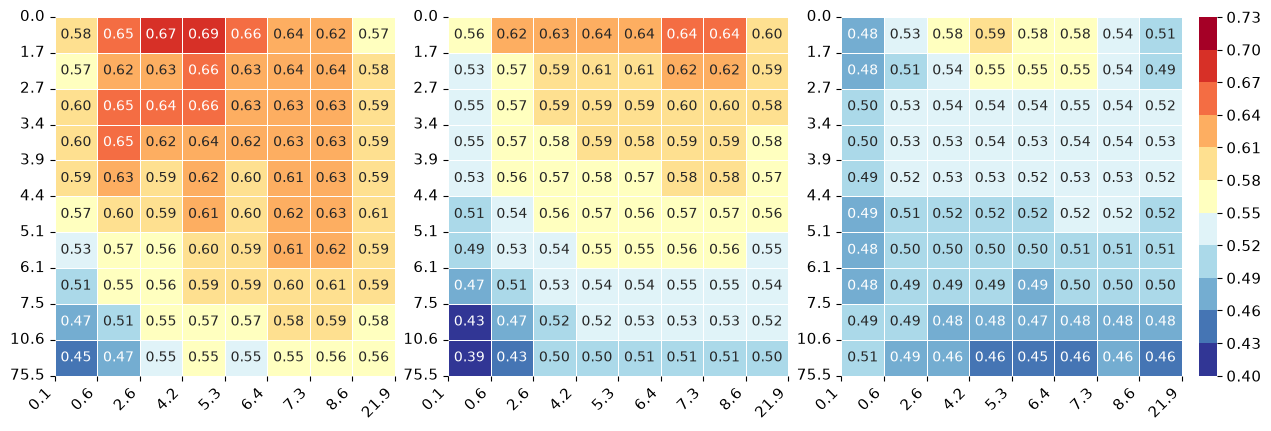

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/anemia_heatmaps_women_15_49.png

smallest cell n = 6,103
  Data                             range 0.45-0.69  income wrong-way 13/72, heat wrong-way 27/70
  With location random effects     range 0.39-0.64  income wrong-way 1/72, heat wrong-way 17/70
  Without location random effects  range 0.45-0.59  income wrong-way 10/72, heat wrong-way 29/70


In [ ]:
# Anemia heatmaps, women 15-49 only ##########################################
#
# The same figure as the cell above, restricted to the people the anemia
# forecasts are actually about. The all-ages version pools every age group in
# the training data - about 74% women 15-49 and 24% children under 5 - while
# inference is only run for women 15-49 (AGE_GROUP_IDS_BY_MEASURE["anemia"] is
# ages 8-14, female). Children also have higher anemia (63% against 51%) and
# make up 38% of the poorest income row but 17% of the richest, so pooling
# them steepens the income gradient for reasons that have nothing to do with
# income.
#
# Who is kept: age_group_id 8-14 AND sex_id 2. Age alone is not enough - 14%
# of the 15-49 rows in this data are men. raw_with_predictions.parquet has no
# sex column, so sex is taken from the model's own training data, which the
# pipeline wrote the predictions onto row for row. That alignment is checked
# below on every column the two files share, and the cell stops if it fails.
#
# Kept identical to the all-ages figure so the two can be compared cell for
# cell: the same bin EDGES (computed on all ages, not re-quantiled on women),
# the same 0.40-0.70 colour scale and the same styling. Re-quantiling on women
# would give each cell more even counts but different edges, and then no cell
# in one figure would correspond to a cell in the other.
ANW_X = "days_over_30C_past_12m"
ANW_Y = "ldi_pc_pd"
ANW_X_Q, ANW_Y_Q = 8, 10
ANW_VMIN, ANW_VMAX = 0.4, 0.7
ANW_AGES = [8, 9, 10, 11, 12, 13, 14]
ANW_FEMALE = 2
ANW_PANELS = [
    ("anemia", "Data"),
    ("fits", "With location random effects"),
    ("no_re_fits", "Without location random effects"),
]
ANW_FIGSIZE, ANW_TICK_SIZE, ANW_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
ANW_OUT = f"{PLOT_OUTPUT}anemia_heatmaps_women_15_49.png"

_anw_model = Path(TRAINING_ANEMIA_PATH)
_anw_spec = yaml.safe_load((_anw_model / "specification.yaml").read_text())
_anw_train = (
    _anw_model.parent.parent
    / "training_data"
    / _anw_spec["version"]["training_data"]
    / "data.parquet"
)
_anw_shared = ["age_group_id", "ihme_loc_id", ANW_X, ANW_Y, "anemia", "year_start"]

_anw = pd.read_parquet(
    _anw_model / "raw_with_predictions.parquet",
    columns=list(dict.fromkeys(_anw_shared + [k for k, _ in ANW_PANELS])),
).reset_index(drop=True)
_anw_t = pd.read_parquet(_anw_train, columns=_anw_shared + ["sex_id"]).reset_index(
    drop=True
)
if len(_anw) != len(_anw_t):
    raise ValueError(f"row counts differ: {len(_anw):,} vs {len(_anw_t):,}")
for _c in _anw_shared:
    _a, _b = _anw[_c], _anw_t[_c]
    if pd.api.types.is_numeric_dtype(_a) and pd.api.types.is_numeric_dtype(_b):
        _same = np.isclose(_a.astype(float), _b.astype(float), equal_nan=True)
    else:
        _same = _a.astype(str).to_numpy() == _b.astype(str).to_numpy()
    if not _same.all():
        raise ValueError(
            f"{_c}: {int((~_same).sum()):,} rows differ - predictions and training "
            "data are not aligned, so sex cannot be borrowed positionally"
        )
_anw["sex_id"] = _anw_t["sex_id"].to_numpy()

# bin edges from ALL ages, exactly as the all-ages figure computes them
_, _anw_xb = pd.qcut(_anw.loc[_anw[ANW_X] > 0, ANW_X], ANW_X_Q, retbins=True)
_, _anw_yb = pd.qcut(_anw[ANW_Y], ANW_Y_Q, retbins=True)

_anw_all = len(_anw)
_anw = _anw[_anw["age_group_id"].isin(ANW_AGES) & (_anw["sex_id"] == ANW_FEMALE)].copy()
print(
    f"women 15-49: {len(_anw):,} of {_anw_all:,} rows "
    f"({100 * len(_anw) / _anw_all:.1f}%)"
)

_anw["_x"] = pd.cut(_anw.loc[_anw[ANW_X] > 0, ANW_X], _anw_xb, include_lowest=True)
_anw["_y"] = pd.cut(_anw[ANW_Y], _anw_yb, include_lowest=True)
_anw_kept = _anw[["_x", "_y"]].notna().all(axis=1)
print(
    f"  {int((~_anw_kept).sum()):,} dropped "
    f"({100 * (1 - _anw_kept.mean()):.1f}%, zero exposure)"
)

ANW_XTICKS = [f"{v:.1f}" for v in _anw_xb]
ANW_YTICKS = [f"{v:.1f}" for v in _anw_yb]
_anw_mats = {
    k: _anw.groupby(["_y", "_x"], observed=False)[k].mean().unstack()
    for k, _ in ANW_PANELS
}
_anw_n = _anw.groupby(["_y", "_x"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 3, figsize=ANW_FIGSIZE, constrained_layout=True)
_anw_step = (ANW_VMAX - ANW_VMIN) / 10
_anw_b = np.arange(ANW_VMIN, ANW_VMAX + _anw_step, _anw_step)
_anw_cmap = plt.get_cmap("RdYlBu_r", len(_anw_b) - 1)
_anw_norm = mcolors.BoundaryNorm(_anw_b, _anw_cmap.N, clip=True)
for ax, (k, label) in zip(axes, ANW_PANELS):
    sns.heatmap(
        _anw_mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": ANW_ANNOT_SIZE, "weight": "regular"},
        cmap=_anw_cmap,
        norm=_anw_norm,
        vmin=ANW_VMIN,
        vmax=ANW_VMAX,
        cbar=(k == ANW_PANELS[-1][0]),
        cbar_kws={"ticks": _anw_b},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(ANW_XTICKS)))
    ax.set_xticklabels(ANW_XTICKS, rotation=45, ha="right", fontsize=ANW_TICK_SIZE)
    ax.set_yticks(range(len(ANW_YTICKS)))
    ax.set_yticklabels(ANW_YTICKS, rotation=0, fontsize=ANW_TICK_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=ANW_TICK_SIZE)
fig.savefig(ANW_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {ANW_OUT}")

print(f"\nsmallest cell n = {int(_anw_n.min().min()):,}")
for k, label in ANW_PANELS:
    m = _anw_mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:32s} range {np.nanmin(m):.2f}-{np.nanmax(m):.2f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )

In [ ]:
# Anemia: scenario lines and cumulative difference table ####################
#
# Identical to the LBW cell, pointed at the anemia results. Checked against
# the pipeline's own table on results 2026_08_01.02: Global 2100
# ssp585 - ssp126 comes out at 1029.42 million against its published 1028.85.
#
# Results 2026_10_16.01 (model 2026_10_14.04), residual step finished
# 2026-10-26 17:29. shifted_prevalence holds ages 8-14 (15-49) for both
# sexes; sex_ids=[2] keeps WOMEN 15-49 only, weighted by their population.
# The table counts person-years with anemia (prevalence x population,
# summed over years), the same arithmetic as the pipeline's table, which
# labels them cases and covers both sexes, so the two will not match.
anemia_counts, anemia_table1, _ = scenario_outputs(
    RESULTS_ANEMIA_PATH,
    ANEMIA_YLABEL,
    ANEMIA_PLOT_FILE,
    ANEMIA_TABLE_FILE,
    sex_ids=[2],
    count_label="person_years_with_anemia",
)
plt.show()
anemia_table1

# SPLINES

### Neonatal splines

In [ ]:
# Neonatal mortality spline effects, stripped back for the deck #############
#
# Rebuilds
#   neonatal_mortality/models/2026_10_08.02/spline_effect_days_over_30C_prev_0_mo.png
#   neonatal_mortality/models/2026_10_08.02/spline_effect_consumption_pd.png
# from the `spline_effect_*.parquet` files the same run wrote, so the curve and
# the band are the pipeline's numbers, not a refit. Each parquet holds 100 rows
# of value / effect / se spanning the observed range of the variable, and the
# band is the pipeline's own effect +/- 1.96 * se.
#
# Kept from plot_scam_spline: the curve at #2c3e50 lw 2.5, the band at #3498db
# alpha 0.2, the dotted grid and the legend.
#
# Removed
# -------
#   rug           the data-density ticks along the bottom
#   knots         the dotted green verticals, and their legend entry
#   title
#   x padding     the pipeline's axis reached far past the data on both sides
#                 because the knot lines sit outside it and matplotlib
#                 autoscaled to meet them. With the knots gone the axis is
#                 pinned to the curve's own first and last value, margins
#                 zeroed so nothing creeps back in.
#   zero line     the red dashed horizontal at y = 0
#   axis labels   both, so the panel can be captioned wherever it lands. The
#                 tick numbers stay - without them the vertical scale, which
#                 is log-odds and not obvious, would be unreadable.
#
# plot_spline_effect_clean and the SPL_* styling constants are in the setup
# cell, shared with the anemia and lbw spline cells below.
NEO_SPL_VARS = ["days_over_30C_prev_0_mo", "consumption_pd"]

for _v in NEO_SPL_VARS:
    _f = Path(TRAINING_28q0_PATH) / f"spline_effect_{_v}.parquet"
    if not _f.exists():
        raise FileNotFoundError(f"{_f} not found")
    _e = pd.read_parquet(_f)
    _out = f"{PLOT_OUTPUT}neonatal_mortality_spline_effect_{_v}.png"
    plot_spline_effect_clean(_e, filepath=_out)
    plt.show()
    print(
        f"{_v}: {len(_e)} points, x {_e['value'].min():.3g} to {_e['value'].max():.3g}, "
        f"effect {_e['effect'].min():+.3f} to {_e['effect'].max():+.3f}"
    )
    print(f"  Saved {_out}")

#### Child mortality splines

In [ ]:
# Child mortality (5q28) spline effects, stripped back for the deck #########
#
# Rebuilds
#   child_mortality/models/2026_10_15.01/spline_effect_days_over_30C_monthly_cumul.png
#   child_mortality/models/2026_10_15.01/spline_effect_consumption_pd_cumul.png
# on the same terms as the neonatal, anemia and lbw spline cells: curve and
# band read straight off the `spline_effect_*.parquet` files that run wrote,
# with the rug, knots, title, x padding, zero line and axis labels removed.
#
# This is the 5q28 fit - deaths between 28 days and 5 years - so it is the
# partner to the neonatal splines above, not a standalone under-5 model. Its
# covariates are the cumulative ones: the climate axis is a monthly average
# over the months a child has lived, and the income axis likewise, which is
# why both carry the `_cumul` suffix.
#
# plot_spline_effect_clean and the SPL_* styling constants come from the
# setup cell at the top.
SPL_MODEL_DIR = Path(TRAINING_5q28_PATH)
SPL_VARS = ["days_over_30C_monthly_cumul", "consumption_pd_cumul"]

for _v in SPL_VARS:
    _f = SPL_MODEL_DIR / f"spline_effect_{_v}.parquet"
    if not _f.exists():
        raise FileNotFoundError(f"{_f} not found")
    _e = pd.read_parquet(_f)
    _out = f"{PLOT_OUTPUT}child_mortality_5q28_spline_effect_{_v}.png"
    plot_spline_effect_clean(_e, filepath=_out)
    plt.show()
    print(
        f"{_v}: {len(_e)} points, x {_e['value'].min():.3g} to {_e['value'].max():.3g}, "
        f"effect {_e['effect'].min():+.3f} to {_e['effect'].max():+.3f}"
    )
    print(f"  Saved {_out}")

#### Anemia splines

In [ ]:
# Anemia spline effects, stripped back for the deck #########################
#
# Rebuilds
#   anemia/models/2026_10_15.01/spline_effect_days_over_30C_past_12m.png
#   anemia/models/2026_10_15.01/spline_effect_ldi_pc_pd.png
# from the `spline_effect_*.parquet` files the same run wrote, so the curve and
# the band are the pipeline's numbers, not a refit. Each parquet holds 100 rows
# of value / effect / se spanning the observed range of the variable, and the
# band is the pipeline's own effect +/- 1.96 * se.
#
# Kept from plot_scam_spline: the curve at #2c3e50 lw 2.5, the band at #3498db
# alpha 0.2, the dotted grid and the legend.
#
# Removed
# -------
#   rug           the data-density ticks along the bottom
#   knots         the dotted green verticals, and their legend entry
#   title
#   x padding     the pipeline's axis ran from about -13 to +35 for days and
#                 -40 to +120 for income, because the knot lines sit far
#                 outside the data and matplotlib autoscaled to reach them.
#                 Roughly 40% of the income figure was blank. With the knots
#                 gone the axis is pinned to the curve's own first and last
#                 value, margins zeroed so nothing creeps back in.
#   zero line     the red dashed horizontal at y = 0
#   axis labels   both, so the panel can be captioned wherever it lands. The
#                 tick numbers stay - without them the vertical scale, which
#                 is log-odds and not obvious, would be unreadable.
#
# plot_spline_effect_clean and the SPL_* styling constants come from the
# setup cell at the top.
#
# The y axis is left to autoscale. It no longer has to leave room for the rug,
# so the curve fills the panel - which is most of what makes these readable at
# the back of a room.
SPL_MODEL_DIR = Path(
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/anemia/models/2026_10_15.01"
)
SPL_VARS = ["days_over_30C_past_12m", "ldi_pc_pd"]

for _v in SPL_VARS:
    _f = SPL_MODEL_DIR / f"spline_effect_{_v}.parquet"
    if not _f.exists():
        raise FileNotFoundError(f"{_f} not found")
    _e = pd.read_parquet(_f)
    _out = f"{PLOT_OUTPUT}anemia_spline_effect_{_v}.png"
    plot_spline_effect_clean(_e, filepath=_out)
    plt.show()
    print(
        f"{_v}: {len(_e)} points, x {_e['value'].min():.3g} to {_e['value'].max():.3g}, "
        f"effect {_e['effect'].min():+.3f} to {_e['effect'].max():+.3f}"
    )
    print(f"  Saved {_out}")

#### LBW splines

In [ ]:
# Low birthweight spline effects, stripped back for the deck ################
#
# Rebuilds
#   lbw/models/2026_10_16.04/spline_effect_days_over_30C_past_9m.png
#   lbw/models/2026_10_16.04/spline_effect_ldi_pc_pd.png
# on the same terms as the neonatal and anemia spline cells: curve and band
# read straight off the `spline_effect_*.parquet` files that run wrote, with
# the rug, knots, title, x padding, zero line and axis labels removed.
#
# plot_spline_effect_clean and the SPL_* styling constants come from the
# setup cell at the top.
SPL_MODEL_DIR = Path(
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/lbw/models/2026_10_16.04"
)
SPL_VARS = ["days_over_30C_past_9m", "ldi_pc_pd"]

for _v in SPL_VARS:
    _f = SPL_MODEL_DIR / f"spline_effect_{_v}.parquet"
    if not _f.exists():
        raise FileNotFoundError(f"{_f} not found")
    _e = pd.read_parquet(_f)
    _out = f"{PLOT_OUTPUT}lbw_spline_effect_{_v}.png"
    plot_spline_effect_clean(_e, filepath=_out)
    plt.show()
    print(
        f"{_v}: {len(_e)} points, x {_e['value'].min():.3g} to {_e['value'].max():.3g}, "
        f"effect {_e['effect'].min():+.3f} to {_e['effect'].max():+.3f}"
    )
    print(f"  Saved {_out}")

# VULNERABILITY MAPS

In [3]:
# Vulnerability map: under-5 mortality (5q0), 2100, SSP5 8.5 - SSP1 2.6 ######
#
# Built pixel by pixel from the two parts the pipeline models, with the same
# survival identities it uses on location values:
#
#     5q28 = 1 - product over age_3_m .. age_60_m of (1 - q)
#     5q0  = 1 - (1 - 28q0) * (1 - 5q28)
#     map  = 1000 * (5q0[ssp585] - 5q0[ssp126])
#
#   28q0  neonatal_mortality/results/2026_10_23.01, 2100 rasters
#   5q28  child_mortality/results/2026_10_23.01, 2100 rasters, one per stratum
#
# Raw rasters, no residual correction, on purpose: the residual and GBD anchor
# are identical across scenarios and cancel out of the difference, and the
# residual step's zero-clipping would hide much of the climate effect - the
# same reason the FHS scenario notebook uses the original model draws. The
# values are therefore the model's own scale, which runs above GBD; the map
# shows where and how much the climate effect falls, in that model's units.
#
# Sex 2 only, because the raster runs were made for sex 2 only. Each raster is
# 18,000 x 36,000 pixels (2.6 GB in memory), and this holds a few at once.
_worse = under5_raster("ssp585")
_better = under5_raster("ssp126")
_worse -= _better
del _better
_worse *= 1000
print(
    f"5q0 difference per 1000: median {np.nanmedian(_worse):.2f}, "
    f"1st-99th percentile {np.nanpercentile(_worse, 1):.2f} to {np.nanpercentile(_worse, 99):.2f}, "
    f"{int(np.isfinite(_worse).sum()):,} pixels"
)
_fig = plot_raster_diff(
    _worse,
    f"Difference in {U5_MAP_LABEL}, year {RASTER_YEAR}\n"
    f"{RASTER_SCENARIO_NAMES['ssp585']} - {RASTER_SCENARIO_NAMES['ssp126']}",
    Path(PLOT_OUTPUT) / U5_MAP_FILE,
)
del _worse
display(_fig)

5q0 difference per 1000: median 0.10, 1st-99th percentile -0.24 to 34.21, 149,877,307 pixels
Wrote /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/under5_mortality_scenario_diff.png


<Figure size 2666.6x906.638 with 2 Axes>